In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
import time

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from scipy.optimize import minimize

In [3]:
# Load data
prices = pd.read_csv("/kaggle/input/datasets/cheryleugene/stok-saham/historical_prices.csv")
prices["date"] = pd.to_datetime(prices["date"])

In [4]:
# DATA OVERVIEW
print("Jumlah baris:", len(prices))
print("Jumlah ticker:", prices["ticker"].nunique())
print("Tanggal awal:", prices["date"].min())
print("Tanggal akhir:", prices["date"].max())

Jumlah baris: 51244
Jumlah ticker: 50
Tanggal awal: 2022-01-03 00:00:00
Tanggal akhir: 2026-08-31 00:00:00


In [5]:
# MISSING VALUES
print(prices.isnull().sum())

# DUPLICATE CHECK
duplicate_count = prices.duplicated(
    ["date", "ticker"]
).sum()

print("Duplicate date-ticker rows:", duplicate_count)

if duplicate_count > 0:
    raise ValueError(
        "Duplicate date-ticker combinations found. "
    )

date              0
ticker            0
adjusted_close    0
volume            0
dtype: int64
Duplicate date-ticker rows: 0


In [6]:
# OBSERVATIONS PER STOCK
observations = prices.groupby("ticker").agg(
    observations=("adjusted_close", "count"),
    first_date=("date", "min"),
    last_date=("date", "max")
)

print(observations.sort_values("observations").head(10))

         observations first_date  last_date
ticker                                     
EMAS.JK           223 2025-09-23 2026-08-31
CDIA.JK           275 2025-07-09 2026-08-31
AADI.JK           406 2024-12-05 2026-08-31
BREN.JK           685 2023-10-09 2026-08-31
AMMN.JK           748 2023-07-07 2026-08-31
MBMA.JK           794 2023-04-18 2026-08-31
NCKL.JK           798 2023-04-12 2026-08-31
CUAN.JK           820 2023-03-08 2026-08-31
MORA.JK           970 2022-08-08 2026-08-31
GOTO.JK          1045 2022-04-11 2026-08-31


In [7]:
# CHECK MISSING DATES WITHIN EACH STOCK'S AVAILABLE PERIOD
all_dates = pd.Index(sorted(prices["date"].dropna().unique()))
gap_results = []

for ticker, group in prices.groupby("ticker"):
    first_date = group["date"].min()
    last_date = group["date"].max()

    # Tanggal yang tersedia pada dataset secara keseluruhan
    # di antara tanggal pertama dan terakhir saham
    expected_dates = all_dates[
        (all_dates >= first_date) &
        (all_dates <= last_date)
    ]

    actual_dates = pd.Index(group["date"].dropna().unique())

    missing_dates = expected_dates.difference(actual_dates)

    gap_results.append({
        "ticker": ticker,
        "first_date": first_date,
        "last_date": last_date,
        "actual_rows": len(actual_dates),
        "expected_dates": len(expected_dates),
        "missing_dates": len(missing_dates),
        "missing_pct": (
            len(missing_dates) / len(expected_dates) * 100
            if len(expected_dates) > 0 else 0
        )
    })

gap_check = pd.DataFrame(gap_results)

print("\nSaham dengan tanggal yang hilang terbanyak:")
print(
    gap_check.sort_values(
        "missing_dates", ascending=False
    ).head(15).to_string(index=False)
)


Saham dengan tanggal yang hilang terbanyak:
 ticker first_date  last_date  actual_rows  expected_dates  missing_dates  missing_pct
AADI.JK 2024-12-05 2026-08-31          406             406              0          0.0
ADMR.JK 2022-01-03 2026-08-31         1112            1112              0          0.0
ADRO.JK 2022-01-03 2026-08-31         1112            1112              0          0.0
AMMN.JK 2023-07-07 2026-08-31          748             748              0          0.0
AMRT.JK 2022-01-03 2026-08-31         1112            1112              0          0.0
ANTM.JK 2022-01-03 2026-08-31         1112            1112              0          0.0
ASII.JK 2022-01-03 2026-08-31         1112            1112              0          0.0
BBCA.JK 2022-01-03 2026-08-31         1112            1112              0          0.0
BBNI.JK 2022-01-03 2026-08-31         1112            1112              0          0.0
BBRI.JK 2022-01-03 2026-08-31         1112            1112              0          0.

In [8]:
# Ubah ke bentuk tabel harga
price_table = prices.pivot(
    index="date",
    columns="ticker",
    values="adjusted_close"
).sort_index()

In [9]:
# Return harian
daily_returns = price_table.pct_change(fill_method=None)

In [10]:
print("Total trading dates:", len(price_table))
print("Total stock columns:", len(daily_returns.columns))
print("Missing daily returns:", int(daily_returns.isna().sum().sum()))

display(price_table.head())
display(daily_returns.head())

Total trading dates: 1112
Total stock columns: 50
Missing daily returns: 4406


ticker,AADI.JK,ADMR.JK,ADRO.JK,AMMN.JK,AMRT.JK,ANTM.JK,ASII.JK,BBCA.JK,BBNI.JK,BBRI.JK,...,PANI.JK,PGUN.JK,PTRO.JK,SMMA.JK,SRAJ.JK,SUPR.JK,TLKM.JK,TPIA.JK,UNTR.JK,UNVR.JK
date,,,,,,,,,,,,,,,,,,,,,
2022-01-03,NaN,125.224693,801.114624,NaN,1130.200073,1812.000854,3831.252441,6253.108398,2551.722900,2973.502686,...,152.520157,394.052399,167.402664,11775.0,314.0,15600.0,3125.690674,1797.421509,12746.706055,3298.706543
2022-01-04,NaN,168.821426,777.453003,NaN,1098.040039,1781.026489,3864.712646,6317.133301,2665.554199,2959.275391,...,141.879211,388.081909,172.904175,11775.0,312.0,15600.0,3118.212891,1791.223633,12805.113281,3314.303223
2022-01-05,NaN,226.332031,757.171631,NaN,1102.634277,1757.795532,3730.869873,6359.816895,2637.096436,2994.843750,...,131.947678,392.062225,174.476028,11775.0,308.0,15600.0,3028.479980,1803.619507,12819.713867,3283.110352
2022-01-06,NaN,281.987427,777.453003,NaN,1061.285522,1726.821167,3797.790771,6381.159180,2637.096436,2959.275391,...,131.238266,382.111420,170.546387,11775.0,318.0,15600.0,3080.824219,1785.025513,12688.303711,3298.706543
2022-01-07,NaN,352.484314,821.395996,NaN,1061.285522,1726.821167,3814.521729,6530.550293,2684.526123,2980.616455,...,128.755402,392.062225,176.833817,11775.0,314.0,15600.0,3118.212891,1797.421509,12951.122070,3290.908691


ticker,AADI.JK,ADMR.JK,ADRO.JK,AMMN.JK,AMRT.JK,ANTM.JK,ASII.JK,BBCA.JK,BBNI.JK,BBRI.JK,...,PANI.JK,PGUN.JK,PTRO.JK,SMMA.JK,SRAJ.JK,SUPR.JK,TLKM.JK,TPIA.JK,UNTR.JK,UNVR.JK
date,,,,,,,,,,,,,,,,,,,,,
2022-01-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2022-01-04,NaN,0.348148,-0.029536,NaN,-0.028455,-0.017094,0.008733,0.010239,0.044610,-0.004785,...,-0.069767,-0.015152,0.032864,0.0,-0.006369,0.0,-0.002392,-0.003448,0.004582,0.004728
2022-01-05,NaN,0.340659,-0.026087,NaN,0.004184,-0.013044,-0.034632,0.006757,-0.010676,0.012019,...,-0.070000,0.010256,0.009091,0.0,-0.012821,0.0,-0.028777,0.006920,0.001140,-0.009412
2022-01-06,NaN,0.245902,0.026786,NaN,-0.037500,-0.017621,0.017937,0.003356,0.000000,-0.011877,...,-0.005376,-0.025381,-0.022523,0.0,0.032468,0.0,0.017284,-0.010309,-0.010251,0.004750
2022-01-07,NaN,0.250000,0.056522,NaN,0.000000,0.000000,0.004405,0.023411,0.017986,0.007212,...,-0.018919,0.026042,0.036866,0.0,-0.012579,0.0,0.012136,0.006944,0.020713,-0.002364


In [11]:
# Statistik return dan risiko
daily_mean = daily_returns.mean()
daily_std = daily_returns.std()

annual_return = daily_mean * 252
annual_volatility = daily_std * np.sqrt(252)

In [12]:
# Return kumulatif berdasarkan harga pertama dan terakhir
first_price = price_table.apply(
    lambda s: s.dropna().iloc[0] if s.notna().any() else np.nan
)
last_price = price_table.apply(
    lambda s: s.dropna().iloc[-1] if s.notna().any() else np.nan
)

total_return = last_price / first_price - 1

In [13]:
# CAGR menggunakan durasi kalender masing-masing saham
first_date = price_table.apply(
    lambda s: s.first_valid_index()
)

last_date = price_table.apply(
    lambda s: s.last_valid_index()
)

years = (
    (last_date - first_date).dt.days / 365.25
).replace(0, np.nan)

cagr = (last_price / first_price) ** (1 / years) - 1

In [14]:
# Drawdown setiap saham
drawdown = price_table.div(
    price_table.cummax()
).sub(1)

max_drawdown = drawdown.min()

In [15]:
summary = pd.DataFrame({
    "observations": daily_returns.count(),
    "mean_daily_return": daily_mean,
    "median_daily_return": daily_returns.median(),
    "daily_return_std": daily_std,
    "annualized_return": annual_return,
    "annualized_volatility": annual_volatility,
    "total_return": total_return,
    "CAGR": cagr,
    "sharpe_ratio_simple": (
        annual_return / annual_volatility.replace(0, np.nan)
    ),
    "max_drawdown": max_drawdown
})

# DESCRIPTIVE STATISTICS
print(summary.describe().round(4))

       observations  mean_daily_return  median_daily_return  daily_return_std  \
count       50.0000            50.0000              50.0000           50.0000   
mean      1023.8800             0.0017              -0.0000            0.0337   
std        213.5365             0.0017               0.0005            0.0125   
min        222.0000            -0.0012              -0.0033            0.0150   
25%       1111.0000             0.0004               0.0000            0.0238   
50%       1111.0000             0.0011               0.0000            0.0320   
75%       1111.0000             0.0025               0.0000            0.0427   
max       1111.0000             0.0059               0.0008            0.0650   

       annualized_return  annualized_volatility  total_return     CAGR  \
count            50.0000                50.0000       50.0000  50.0000   
mean              0.4220                 0.5352        5.1009   0.3536   
std               0.4254                 0.1985 

In [16]:
# TOP 10 TOTAL RETURN
print(
    summary.sort_values("total_return", ascending=False)
    .head(10).round(4)
)

         observations  mean_daily_return  median_daily_return  \
ticker                                                          
SRAJ.JK          1111             0.0042                  0.0   
PANI.JK          1111             0.0044                  0.0   
PTRO.JK          1111             0.0041                  0.0   
CUAN.JK           819             0.0059                  0.0   
PGUN.JK          1111             0.0043                  0.0   
ADMR.JK          1111             0.0032                  0.0   
MPRO.JK          1111             0.0034                  0.0   
MORA.JK           969             0.0035                  0.0   
MLPT.JK          1111             0.0035                  0.0   
BRMS.JK          1111             0.0026                  0.0   

         daily_return_std  annualized_return  annualized_volatility  \
ticker                                                                
SRAJ.JK            0.0417             1.0650                 0.6621   
PANI.J

In [17]:
# TOP 10 CAGR
print(
    summary.sort_values("CAGR", ascending=False)
    .head(10).round(4)
)

         observations  mean_daily_return  median_daily_return  \
ticker                                                          
EMAS.JK           222             0.0055               0.0000   
CUAN.JK           819             0.0059               0.0000   
CDIA.JK           274             0.0055              -0.0033   
SRAJ.JK          1111             0.0042               0.0000   
PANI.JK          1111             0.0044               0.0000   
PTRO.JK          1111             0.0041               0.0000   
PGUN.JK          1111             0.0043               0.0000   
MORA.JK           969             0.0035               0.0000   
ADMR.JK          1111             0.0032               0.0000   
MPRO.JK          1111             0.0034               0.0000   

         daily_return_std  annualized_return  annualized_volatility  \
ticker                                                                
EMAS.JK            0.0477             1.3924                 0.7569   
CUAN.J

In [18]:
# TOP 10 VOLATILITY
print(
    summary.sort_values("annualized_volatility", ascending=False)
    .head(10).round(4)
)

         observations  mean_daily_return  median_daily_return  \
ticker                                                          
CDIA.JK           274             0.0055              -0.0033   
CUAN.JK           819             0.0059               0.0000   
MLPT.JK          1111             0.0035               0.0000   
BREN.JK           684             0.0032               0.0000   
PGUN.JK          1111             0.0043               0.0000   
PANI.JK          1111             0.0044               0.0000   
MPRO.JK          1111             0.0034               0.0000   
EMAS.JK           222             0.0055               0.0000   
MORA.JK           969             0.0035               0.0000   
PTRO.JK          1111             0.0041               0.0000   

         daily_return_std  annualized_return  annualized_volatility  \
ticker                                                                
CDIA.JK            0.0650             1.3852                 1.0316   
CUAN.J

In [19]:
# TOP 10 DEEPEST DRAWDOWN
print(
    summary.sort_values("max_drawdown")
    .head(10).round(4)
)

         observations  mean_daily_return  median_daily_return  \
ticker                                                          
MLPT.JK          1111             0.0035                  0.0   
DSSA.JK          1111             0.0024                  0.0   
TPIA.JK          1111             0.0009                  0.0   
GOTO.JK          1044            -0.0012                  0.0   
CUAN.JK           819             0.0059                  0.0   
MDKA.JK          1111             0.0003                  0.0   
PGUN.JK          1111             0.0043                  0.0   
BREN.JK           684             0.0032                  0.0   
UNVR.JK          1111            -0.0002                  0.0   
INCO.JK          1111             0.0006                  0.0   

         daily_return_std  annualized_return  annualized_volatility  \
ticker                                                                
MLPT.JK            0.0542             0.8906                 0.8604   
DSSA.J

In [20]:
# Periksa return harian ekstrem
returns_long = daily_returns.stack().rename("daily_return").reset_index()
returns_long.columns = ["date", "ticker", "daily_return"]

extreme_returns = returns_long[
    returns_long["daily_return"].abs() > 0.20
].sort_values("daily_return", ascending=False)

print("Jumlah return harian dengan perubahan lebih dari 20%:",
      len(extreme_returns))

print(extreme_returns.head(20).round(4))

Jumlah return harian dengan perubahan lebih dari 20%: 159
            date   ticker  daily_return
7135  2022-09-23  SRAJ.JK        0.3500
14234 2023-05-31  GOTO.JK        0.3486
0     2022-01-04  ADMR.JK        0.3481
40    2022-01-05  ADMR.JK        0.3407
41810 2025-11-11  BUMI.JK        0.3200
49830 2026-07-21  MLPT.JK        0.2524
20163 2023-12-07  TPIA.JK        0.2500
120   2022-01-07  ADMR.JK        0.2500
37712 2025-07-15  CDIA.JK        0.2500
48056 2026-05-29  BREN.JK        0.2500
1430  2022-02-23  PANI.JK        0.2500
20250 2023-12-11  PANI.JK        0.2500
37565 2025-07-10  CDIA.JK        0.2500
20064 2023-12-05  PTRO.JK        0.2500
8180  2022-10-28  MPRO.JK        0.2500
17995 2023-10-04  MPRO.JK        0.2500
12244 2023-03-15  CUAN.JK        0.2500
8311  2022-11-02  SRAJ.JK        0.2500
20771 2023-12-28  SRAJ.JK        0.2500
26452 2024-07-12  MPRO.JK        0.2500


In [21]:
# Hitung berapa banyak return harian yang nol
zero_return_pct = (
    daily_returns.eq(0).sum() /
    daily_returns.notna().sum() * 100
).sort_values(ascending=False)

print("Saham dengan persentase return nol tertinggi:")
print(zero_return_pct.head(10).round(2))

Saham dengan persentase return nol tertinggi:
ticker
SUPR.JK    91.99
SMMA.JK    66.34
DSSA.JK    38.88
MPRO.JK    37.26
SRAJ.JK    36.09
DCII.JK    34.83
CASA.JK    34.65
PGUN.JK    28.80
GOTO.JK    27.39
DNET.JK    27.27
dtype: float64


In [22]:
# Gabungkan harga dengan return harian
price_long = price_table.stack().rename(
    "adjusted_close"
).reset_index()

price_long.columns = ["date", "ticker", "adjusted_close"]

returns_long = daily_returns.stack().rename(
    "daily_return"
).reset_index()

returns_long.columns = ["date", "ticker", "daily_return"]

In [23]:
# Ambil return ekstrem
extreme_returns = returns_long[
    returns_long["daily_return"].abs() > 0.20
].copy()

# Gabungkan dengan harga
extreme_check = extreme_returns.merge(
    price_long,
    on=["date", "ticker"],
    how="left"
)

In [24]:
# Cari harga sebelumnya dan sesudahnya
extreme_check["previous_price"] = extreme_check.apply(
    lambda r: price_table.loc[
        price_table.index < r["date"], r["ticker"]
    ].dropna().iloc[-1]
    if (
        (price_table.index < r["date"]).any()
        and price_table.loc[
            price_table.index < r["date"], r["ticker"]
        ].notna().any()
    ) else np.nan,
    axis=1
)

extreme_check["next_price"] = extreme_check.apply(
    lambda r: price_table.loc[
        price_table.index > r["date"], r["ticker"]
    ].dropna().iloc[0]
    if (
        (price_table.index > r["date"]).any()
        and price_table.loc[
            price_table.index > r["date"], r["ticker"]
        ].notna().any()
    ) else np.nan,
    axis=1
)

print(
    extreme_check[
        [
            "date", "ticker", "previous_price",
            "adjusted_close", "next_price", "daily_return"
        ]
    ].sort_values("daily_return", ascending=False).head(30).round(4)
)

          date   ticker  previous_price  adjusted_close  next_price  \
23  2022-09-23  SRAJ.JK        100.0000        135.0000    141.0000   
42  2023-05-31  GOTO.JK        109.0000        147.0000    125.0000   
0   2022-01-04  ADMR.JK        125.2247        168.8214    226.3320   
1   2022-01-05  ADMR.JK        168.8214        226.3320    281.9874   
130 2025-11-11  BUMI.JK        150.0000        198.0000    192.0000   
155 2026-07-21  MLPT.JK       1038.0000       1300.0000   1625.0000   
67  2023-12-07  TPIA.JK       3461.9807       4327.4766   4675.6641   
3   2022-01-07  ADMR.JK        281.9874        352.4843    439.6778   
105 2025-07-15  CDIA.JK        494.8207        618.5259    771.9203   
141 2026-05-29  BREN.JK       2636.6748       3295.8438   4114.8110   
10  2022-02-23  PANI.JK        249.7074        312.1343    353.9886   
69  2023-12-11  PANI.JK       4692.9224       5866.1533   5067.3574   
101 2025-07-10  CDIA.JK        253.3482        316.6853    395.8566   
64  20

In [25]:
# Pilih 10 observasi ekstrem teratas
extreme_dates = extreme_check.sort_values(
    "daily_return", ascending=False
).head(10)

for _, row in extreme_dates.iterrows():
    ticker = row["ticker"]
    date = pd.Timestamp(row["date"])

    series = price_table[ticker].dropna()

    # Ambil 3 observasi sebelum dan sesudah tanggal ekstrem
    window = series.loc[
        (series.index >= date - pd.Timedelta(days=7)) &
        (series.index <= date + pd.Timedelta(days=7))
    ]

    print(f"\n=== {ticker} | {date.date()} ===")
    print(window)


=== SRAJ.JK | 2022-09-23 ===
date
2022-09-16    132.0
2022-09-19    123.0
2022-09-20    115.0
2022-09-21    107.0
2022-09-22    100.0
2022-09-23    135.0
2022-09-26    141.0
2022-09-27    163.0
2022-09-28    152.0
2022-09-29    169.0
2022-09-30    158.0
Name: SRAJ.JK, dtype: float64

=== GOTO.JK | 2023-05-31 ===
date
2023-05-24    114.0
2023-05-25    111.0
2023-05-26    104.0
2023-05-29    108.0
2023-05-30    109.0
2023-05-31    147.0
2023-06-05    125.0
2023-06-06    119.0
2023-06-07    116.0
Name: GOTO.JK, dtype: float64

=== ADMR.JK | 2022-01-04 ===
date
2022-01-03    125.224693
2022-01-04    168.821426
2022-01-05    226.332031
2022-01-06    281.987427
2022-01-07    352.484314
2022-01-10    439.677795
2022-01-11    547.278259
Name: ADMR.JK, dtype: float64

=== ADMR.JK | 2022-01-05 ===
date
2022-01-03    125.224693
2022-01-04    168.821426
2022-01-05    226.332031
2022-01-06    281.987427
2022-01-07    352.484314
2022-01-10    439.677795
2022-01-11    547.278259
2022-01-12    681.77

In [26]:
check_tickers = ["ADMR.JK", "CDIA.JK", "GOTO.JK", "SRAJ.JK"]

for ticker in check_tickers:
    raw = yf.download(
        ticker,
        start="2022-01-01",
        end="2026-09-01",
        auto_adjust=False,
        progress=False
    )

    if raw.empty:
        print(f"\n{ticker}: data tidak tersedia")
        continue

    print(f"\n=== {ticker} ===")

    # Tangani format kolom MultiIndex dari yfinance
    if isinstance(raw.columns, pd.MultiIndex):
        raw.columns = raw.columns.get_level_values(0)

    cols = [c for c in ["Close", "Adj Close", "Volume"] if c in raw.columns]
    print(raw[cols].loc["2022-01-01":"2022-01-15"].tail(10))


=== ADMR.JK ===
Price       Close   Adj Close     Volume
Date                                    
2022-01-03  135.0  125.224693   34289600
2022-01-04  182.0  168.821426   22170900
2022-01-05  244.0  226.332031   43203600
2022-01-06  304.0  281.987427   52097500
2022-01-07  380.0  352.484314   19248600
2022-01-10  474.0  439.677795   17843500
2022-01-11  590.0  547.278259  685732700
2022-01-12  735.0  681.778870  457330400
2022-01-13  735.0  681.778870          0
2022-01-14  790.0  732.796265  378668200

=== CDIA.JK ===
Empty DataFrame
Columns: [Close, Adj Close, Volume]
Index: []

=== GOTO.JK ===
Empty DataFrame
Columns: [Close, Adj Close, Volume]
Index: []

=== SRAJ.JK ===
Price       Close  Adj Close   Volume
Date                                 
2022-01-03  314.0      314.0  1102000
2022-01-04  312.0      312.0  1263300
2022-01-05  308.0      308.0   615300
2022-01-06  318.0      318.0   903000
2022-01-07  314.0      314.0   772900
2022-01-10  316.0      316.0   978100
2022-01-11  

In [27]:
check_periods = {
    "ADMR.JK": ("2022-01-03", "2022-01-15"),
    "SRAJ.JK": ("2022-09-19", "2022-10-01"),
    "GOTO.JK": ("2023-05-24", "2023-06-10"),
    "CDIA.JK": ("2025-07-09", "2025-07-25")
}

for ticker, (start, end) in check_periods.items():
    raw = yf.download(
        ticker,
        start=start,
        end=end,
        auto_adjust=False,
        progress=False
    )

    print(f"\n=== {ticker} ===")

    if raw.empty:
        print("Tidak ada data pada periode ini.")
        continue

    if isinstance(raw.columns, pd.MultiIndex):
        raw.columns = raw.columns.get_level_values(0)

    cols = [
        c for c in ["Close", "Adj Close", "Volume"]
        if c in raw.columns
    ]

    print(raw[cols])


=== ADMR.JK ===
Price       Close   Adj Close     Volume
Date                                    
2022-01-03  135.0  125.224686   34289600
2022-01-04  182.0  168.821442   22170900
2022-01-05  244.0  226.332031   43203600
2022-01-06  304.0  281.987457   52097500
2022-01-07  380.0  352.484314   19248600
2022-01-10  474.0  439.677795   17843500
2022-01-11  590.0  547.278259  685732700
2022-01-12  735.0  681.778870  457330400
2022-01-13  735.0  681.778870          0
2022-01-14  790.0  732.796326  378668200

=== SRAJ.JK ===
Price       Close  Adj Close     Volume
Date                                   
2022-09-19  123.0      123.0   17570000
2022-09-20  115.0      115.0    7627200
2022-09-21  107.0      107.0    4987400
2022-09-22  100.0      100.0   10720000
2022-09-23  135.0      135.0   62259400
2022-09-26  141.0      141.0  163713900
2022-09-27  163.0      163.0   80275100
2022-09-28  152.0      152.0  108151600
2022-09-29  169.0      169.0   56420900
2022-09-30  158.0      158.0   168

In [28]:
# Periksa volume nol
zero_volume = prices[prices["volume"] == 0]

print("Jumlah baris dengan volume nol:", len(zero_volume))

print("\nSaham dengan volume nol terbanyak:")
print(
    zero_volume.groupby("ticker")
    .size()
    .sort_values(ascending=False)
    .head(15)
)

print("\nContoh observasi volume nol:")
print(
    zero_volume[
        ["date", "ticker", "adjusted_close", "volume"]
    ].head(20)
)

Jumlah baris dengan volume nol: 2297

Saham dengan volume nol terbanyak:
ticker
SUPR.JK    970
SMMA.JK    309
DSSA.JK    301
MPRO.JK    189
DCII.JK    145
PGUN.JK    137
SRAJ.JK     89
MLPT.JK     30
CUAN.JK     28
MORA.JK     22
CASA.JK     21
IMPC.JK      9
ADMR.JK      8
PANI.JK      8
BREN.JK      7
dtype: int64

Contoh observasi volume nol:
            date   ticker  adjusted_close  volume
414   2022-01-13  ADMR.JK      681.778870       0
422   2022-01-25  ADMR.JK      973.969788       0
423   2022-01-26  ADMR.JK      973.969788       0
424   2022-01-27  ADMR.JK      973.969788       0
453   2022-03-14  ADMR.JK     1553.713745       0
900   2024-01-15  ADMR.JK     1256.884888       0
945   2024-03-25  ADMR.JK     1205.867310       0
946   2024-03-26  ADMR.JK     1205.867310       0
2760  2024-01-15  AMMN.JK     7325.000000       0
2805  2024-03-25  AMMN.JK     8775.000000       0
2806  2024-03-26  AMMN.JK     8775.000000       0
12056 2025-09-30  BNLI.JK     5888.569336       0
12

In [29]:
# Jumlah saham dengan volume nol pada setiap tanggal
zero_volume_by_date = (
    prices[prices["volume"] == 0]
    .groupby("date")["ticker"]
    .nunique()
    .sort_values(ascending=False)
)

print("Tanggal dengan saham volume nol terbanyak:")
print(zero_volume_by_date.head(20))

# Tampilkan tanggal yang memiliki setidaknya 10 saham volume nol
print("\nTanggal dengan >= 10 saham volume nol:")
print(zero_volume_by_date[zero_volume_by_date >= 10])

Tanggal dengan saham volume nol terbanyak:
date
2024-03-26    11
2024-03-25    11
2024-01-15    11
2022-11-18     7
2022-11-04     6
2022-11-03     6
2022-11-08     6
2024-05-15     6
2022-11-17     6
2023-04-05     5
2023-04-13     5
2022-07-25     5
2022-07-21     5
2022-11-21     5
2023-11-10     5
2023-01-27     5
2023-12-21     5
2023-02-20     5
2023-12-22     5
2024-01-10     5
Name: ticker, dtype: int64

Tanggal dengan >= 10 saham volume nol:
date
2024-03-26    11
2024-03-25    11
2024-01-15    11
Name: ticker, dtype: int64


In [30]:
# Tanggal dengan jumlah saham bervolume nol terbanyak
check_dates = [
    "2024-01-15",
    "2024-03-25",
    "2024-03-26"
]

zero_volume_details = prices[
    (prices["date"].astype(str).isin(check_dates)) &
    (prices["volume"] == 0)
].sort_values(["date", "ticker"])

print(
    zero_volume_details[
        ["date", "ticker", "adjusted_close", "volume"]
    ].to_string(index=False)
)

      date  ticker  adjusted_close  volume
2024-01-15 ADMR.JK     1256.884888       0
2024-01-15 AMMN.JK     7325.000000       0
2024-01-15 BREN.JK     4690.542480       0
2024-01-15 CUAN.JK     1342.500000       0
2024-01-15 DCII.JK    40000.000000       0
2024-01-15 GOTO.JK       91.000000       0
2024-01-15 MBMA.JK      575.000000       0
2024-01-15 MORA.JK      454.000000       0
2024-01-15 NCKL.JK      836.192932       0
2024-01-15 SMMA.JK    14500.000000       0
2024-01-15 SUPR.JK    39900.000000       0
2024-03-25 ADMR.JK     1205.867310       0
2024-03-25 AMMN.JK     8775.000000       0
2024-03-25 BREN.JK     5339.234375       0
2024-03-25 CUAN.JK      494.000000       0
2024-03-25 DCII.JK    35825.000000       0
2024-03-25 GOTO.JK       68.000000       0
2024-03-25 MBMA.JK      488.000000       0
2024-03-25 MORA.JK      460.000000       0
2024-03-25 NCKL.JK      796.583740       0
2024-03-25 SRAJ.JK     1715.000000       0
2024-03-25 SUPR.JK    39900.000000       0
2024-03-26 

In [31]:
prices = prices.sort_values(["ticker", "date"]).copy()

prices["previous_price"] = (
    prices.groupby("ticker")["adjusted_close"].shift(1)
)

prices["daily_return"] = (
    prices.groupby("ticker")["adjusted_close"].pct_change(fill_method=None)
)

check = prices[
    (prices["date"].astype(str).isin(check_dates)) &
    (prices["volume"] == 0)
]

print(
    check[
        [
            "date", "ticker", "previous_price",
            "adjusted_close", "daily_return", "volume"
        ]
    ].to_string(index=False)
)

      date  ticker  previous_price  adjusted_close  daily_return  volume
2024-01-15 ADMR.JK     1256.884888     1256.884888           0.0       0
2024-03-25 ADMR.JK     1205.867310     1205.867310           0.0       0
2024-03-26 ADMR.JK     1205.867310     1205.867310           0.0       0
2024-01-15 AMMN.JK     7325.000000     7325.000000           0.0       0
2024-03-25 AMMN.JK     8775.000000     8775.000000           0.0       0
2024-03-26 AMMN.JK     8775.000000     8775.000000           0.0       0
2024-01-15 BREN.JK     4690.542480     4690.542480           0.0       0
2024-03-25 BREN.JK     5339.234375     5339.234375           0.0       0
2024-03-26 BREN.JK     5339.234375     5339.234375           0.0       0
2024-01-15 CUAN.JK     1342.500000     1342.500000           0.0       0
2024-03-25 CUAN.JK      494.000000      494.000000           0.0       0
2024-03-26 CUAN.JK      494.000000      494.000000           0.0       0
2024-01-15 DCII.JK    40000.000000    40000.000000 

In [32]:
check_dates = [
    "2024-01-15",
    "2024-03-25",
    "2024-03-26"
]

tickers_to_check = [
    "ADMR.JK", "AMMN.JK", "BREN.JK", "CUAN.JK",
    "DCII.JK", "GOTO.JK", "MBMA.JK", "MORA.JK",
    "NCKL.JK", "SRAJ.JK", "SUPR.JK"
]

prices["date"] = pd.to_datetime(prices["date"])

check = prices[
    prices["ticker"].isin(tickers_to_check)
    & prices["date"].between(
        "2024-01-11", "2024-03-28"
    )
].copy()

check["daily_return"] = (
    check.groupby("ticker")["adjusted_close"].pct_change()
)

for date in pd.to_datetime(check_dates):
    print(f"\n=== {date.date()} ===")
    print(
        check[
            check["date"].between(
                date - pd.Timedelta(days=2),
                date + pd.Timedelta(days=2)
            )
        ][
            ["date", "ticker", "adjusted_close",
             "volume", "daily_return"]
        ].to_string(index=False)
    )


=== 2024-01-15 ===
      date  ticker  adjusted_close     volume  daily_return
2024-01-15 ADMR.JK     1256.884888          0      0.000000
2024-01-16 ADMR.JK     1219.781250   11688000     -0.029520
2024-01-17 ADMR.JK     1191.953491   30140200     -0.022814
2024-01-15 AMMN.JK     7325.000000          0      0.000000
2024-01-16 AMMN.JK     7425.000000   28214800      0.013652
2024-01-17 AMMN.JK     7200.000000   35689900     -0.030303
2024-01-15 BREN.JK     4690.542480          0      0.000000
2024-01-16 BREN.JK     4870.180176   70243100      0.038298
2024-01-17 BREN.JK     5139.636719   65649600      0.055328
2024-01-15 CUAN.JK     1342.500000          0      0.000000
2024-01-16 CUAN.JK     1210.000000   13305000     -0.098696
2024-01-17 CUAN.JK     1090.000000    5624000     -0.099174
2024-01-15 DCII.JK    40000.000000          0      0.000000
2024-01-16 DCII.JK    39875.000000        400     -0.003125
2024-01-17 DCII.JK    39875.000000        100      0.000000
2024-01-15 GOTO.JK  

In [33]:
# Cari periode volume nol berturut-turut per saham
prices = prices.sort_values(["ticker", "date"]).copy()

prices["zero_volume"] = prices["volume"].eq(0)

prices["zero_group"] = (
    prices.groupby("ticker")["zero_volume"]
    .transform(lambda s: s.ne(s.shift()).cumsum())
)

zero_periods = (
    prices[prices["zero_volume"]]
    .groupby(["ticker", "zero_group"])
    .agg(
        start_date=("date", "min"),
        end_date=("date", "max"),
        days=("date", "size"),
        first_price=("adjusted_close", "first"),
        last_price=("adjusted_close", "last")
    )
    .reset_index()
)

print(
    zero_periods[zero_periods["days"] >= 3]
    .sort_values("days", ascending=False)
    .head(20)
)

      ticker  zero_group start_date   end_date  days  first_price  last_price
598  SUPR.JK         128 2025-04-15 2026-08-31   327      43850.0     43850.0
594  SUPR.JK         120 2024-09-03 2025-02-20   114      43875.0     43875.0
585  SUPR.JK         102 2023-07-24 2023-11-02    72      34000.0     34000.0
589  SUPR.JK         110 2024-01-05 2024-04-05    60      39900.0     39900.0
591  SUPR.JK         114 2024-04-22 2024-07-22    59      39125.0     39125.0
523  SRAJ.JK          10 2024-03-20 2024-05-27    37       1715.0      1715.0
584  SUPR.JK         100 2023-05-30 2023-07-20    32      34000.0     34000.0
588  SUPR.JK         108 2023-11-29 2024-01-03    23      39900.0     39900.0
593  SUPR.JK         118 2024-08-01 2024-08-30    22      43875.0     43875.0
276  MPRO.JK          28 2022-11-03 2022-11-30    20       1755.0      1755.0
13   CASA.JK           2 2023-12-01 2023-12-29    19        620.0       620.0
482  SMMA.JK         180 2023-08-31 2023-09-22    17      12900.

In [34]:
# Hitung proporsi volume nol per saham
quality_check = (
    prices.groupby("ticker")
    .agg(
        total_rows=("volume", "size"),
        zero_volume_rows=("volume", lambda x: (x == 0).sum()),
        zero_volume_ratio=("volume", lambda x: (x == 0).mean()),
        unique_prices=("adjusted_close", "nunique")
    )
    .reset_index()
)

quality_check["zero_volume_pct"] = (
    quality_check["zero_volume_ratio"] * 100
)

quality_check = quality_check.sort_values(
    "zero_volume_pct", ascending=False
)

print(
    quality_check[
        [
            "ticker", "total_rows", "zero_volume_rows",
            "zero_volume_pct", "unique_prices"
        ]
    ].to_string(index=False)
)

 ticker  total_rows  zero_volume_rows  zero_volume_pct  unique_prices
SUPR.JK        1112               970        87.230216             85
SMMA.JK        1112               309        27.787770            187
DSSA.JK        1112               301        27.068345            565
MPRO.JK        1112               189        16.996403            343
DCII.JK        1112               145        13.039568            519
PGUN.JK        1112               137        12.320144            372
SRAJ.JK        1112                89         8.003597            370
CUAN.JK         820                28         3.414634            425
MLPT.JK        1112                30         2.697842            642
MORA.JK         970                22         2.268041            234
CASA.JK        1112                21         1.888489            208
CDIA.JK         275                 3         1.090909            180
BREN.JK         685                 7         1.021898            423
IMPC.JK        1112 

In [35]:
activity_check = (
    prices.groupby("ticker")
    .agg(
        total_rows=("volume", "size"),
        positive_volume_days=("volume", lambda x: (x > 0).sum()),
        zero_volume_days=("volume", lambda x: (x == 0).sum()),
        unique_prices=("adjusted_close", "nunique")
    )
    .reset_index()
)

activity_check["positive_volume_pct"] = (
    activity_check["positive_volume_days"]
    / activity_check["total_rows"] * 100
)

print(
    activity_check.sort_values("positive_volume_pct")[
        [
            "ticker", "total_rows",
            "positive_volume_days", "zero_volume_days",
            "positive_volume_pct", "unique_prices"
        ]
    ].to_string(index=False)
)

 ticker  total_rows  positive_volume_days  zero_volume_days  positive_volume_pct  unique_prices
SUPR.JK        1112                   142               970            12.769784             85
SMMA.JK        1112                   803               309            72.212230            187
DSSA.JK        1112                   811               301            72.931655            565
MPRO.JK        1112                   923               189            83.003597            343
DCII.JK        1112                   967               145            86.960432            519
PGUN.JK        1112                   975               137            87.679856            372
SRAJ.JK        1112                  1023                89            91.996403            370
CUAN.JK         820                   792                28            96.585366            425
MLPT.JK        1112                  1082                30            97.302158            642
MORA.JK         970                   94

In [36]:
# Tandai saham dengan volume nol >= 10%
quality_check["needs_review"] = (
    quality_check["zero_volume_pct"] >= 10
)

# Urutkan saham dari persentase volume nol tertinggi
review_list = quality_check[
    quality_check["needs_review"]
].sort_values(
    "zero_volume_pct",
    ascending=False
)

# Tampilkan hasil pemeriksaan
print(
    review_list[
        [
            "ticker",
            "total_rows",
            "zero_volume_rows",
            "zero_volume_pct",
            "unique_prices"
        ]
    ].to_string(index=False)
)

 ticker  total_rows  zero_volume_rows  zero_volume_pct  unique_prices
SUPR.JK        1112               970        87.230216             85
SMMA.JK        1112               309        27.787770            187
DSSA.JK        1112               301        27.068345            565
MPRO.JK        1112               189        16.996403            343
DCII.JK        1112               145        13.039568            519
PGUN.JK        1112               137        12.320144            372


In [37]:
prices = prices.sort_values(["ticker", "date"]).copy()

prices["previous_price"] = (
    prices.groupby("ticker")["adjusted_close"].shift(1)
)

prices["price_unchanged"] = (
    prices["adjusted_close"].eq(prices["previous_price"])
)

zero_volume_check = (
    prices.groupby("ticker")
    .apply(
        lambda g: pd.Series({
            "zero_volume_rows": (g["volume"] == 0).sum(),
            "zero_volume_price_unchanged": (
                (g["volume"] == 0) &
                g["price_unchanged"]
            ).sum()
        }),
        include_groups=False
    )
    .reset_index()
)

zero_volume_check["unchanged_pct_of_zero_volume"] = (
    zero_volume_check["zero_volume_price_unchanged"] /
    zero_volume_check["zero_volume_rows"].replace(0, np.nan) * 100
)

print(
    zero_volume_check.sort_values(
        "unchanged_pct_of_zero_volume",
        ascending=False
    ).to_string(index=False)
)

 ticker  zero_volume_rows  zero_volume_price_unchanged  unchanged_pct_of_zero_volume
ADMR.JK                 8                            8                         100.0
AMMN.JK                 3                            3                         100.0
BNLI.JK                 1                            1                         100.0
BREN.JK                 7                            7                         100.0
CASA.JK                21                           21                         100.0
CDIA.JK                 3                            3                         100.0
CUAN.JK                28                           28                         100.0
DCII.JK               145                          145                         100.0
DNET.JK                 4                            4                         100.0
DSSA.JK               301                          301                         100.0
PANI.JK                 8                            8           

In [38]:
prices = prices.sort_values(["ticker", "date"]).copy()

prices["previous_price"] = (
    prices.groupby("ticker")["adjusted_close"].shift(1)
)

prices["price_unchanged"] = (
    prices["adjusted_close"] == prices["previous_price"]
)

stagnation_check = (
    prices.groupby("ticker")
    .agg(
        total_rows=("adjusted_close", "size"),
        unchanged_price_days=("price_unchanged", "sum"),
        unique_prices=("adjusted_close", "nunique")
    )
    .reset_index()
)

stagnation_check["unchanged_price_pct"] = (
    stagnation_check["unchanged_price_days"]
    / (stagnation_check["total_rows"] - 1).clip(lower=1)
    * 100
)

print(
    stagnation_check.sort_values(
        "unchanged_price_pct", ascending=False
    ).to_string(index=False)
)

 ticker  total_rows  unchanged_price_days  unique_prices  unchanged_price_pct
SUPR.JK        1112                  1022             85            91.989199
SMMA.JK        1112                   737            187            66.336634
DSSA.JK        1112                   432            565            38.883888
MPRO.JK        1112                   414            343            37.263726
SRAJ.JK        1112                   401            370            36.093609
DCII.JK        1112                   387            519            34.833483
CASA.JK        1112                   385            208            34.653465
PGUN.JK        1112                   320            372            28.802880
GOTO.JK        1045                   286            173            27.394636
DNET.JK        1112                   303            241            27.272727
MORA.JK         970                   208            234            21.465428
BNLI.JK        1112                   226            426        

In [39]:
summary.to_csv("descriptive_summary.csv")

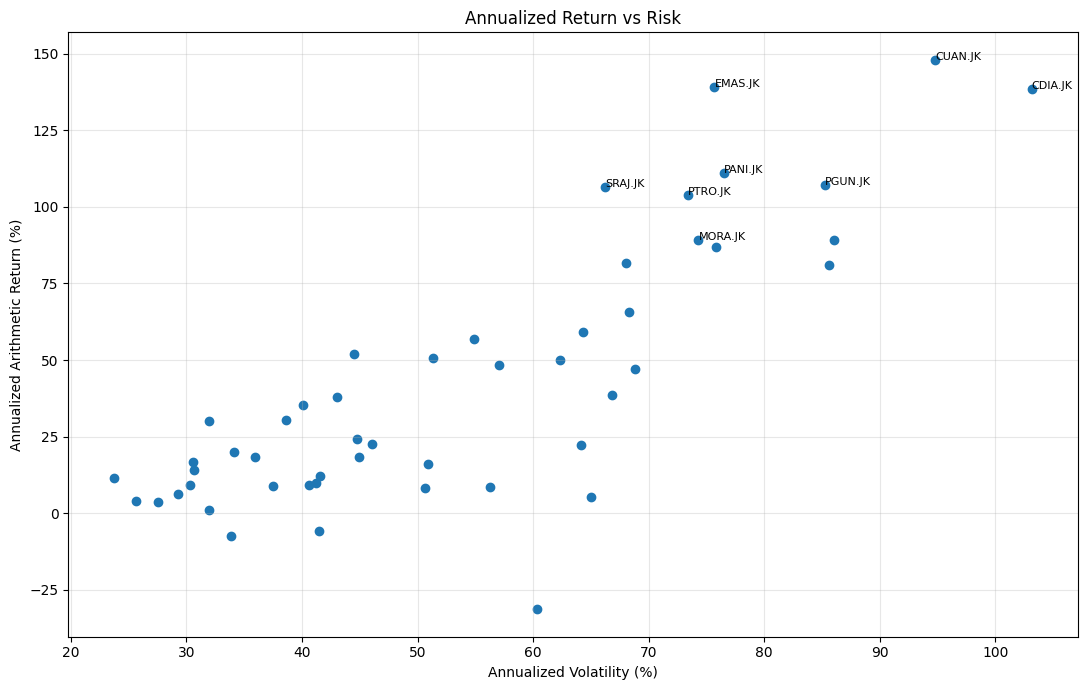

In [40]:
# Return vs Risk
plot_data = summary.dropna(
    subset=["annualized_return", "annualized_volatility"]
)

plt.figure(figsize=(11, 7))
plt.scatter(
    plot_data["annualized_volatility"] * 100,
    plot_data["annualized_return"] * 100
)

for ticker in plot_data.nlargest(8, "annualized_return").index:
    plt.annotate(
        ticker,
        (
            plot_data.loc[ticker, "annualized_volatility"] * 100,
            plot_data.loc[ticker, "annualized_return"] * 100
        ),
        fontsize=8
    )

plt.title("Annualized Return vs Risk")
plt.xlabel("Annualized Volatility (%)")
plt.ylabel("Annualized Arithmetic Return (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

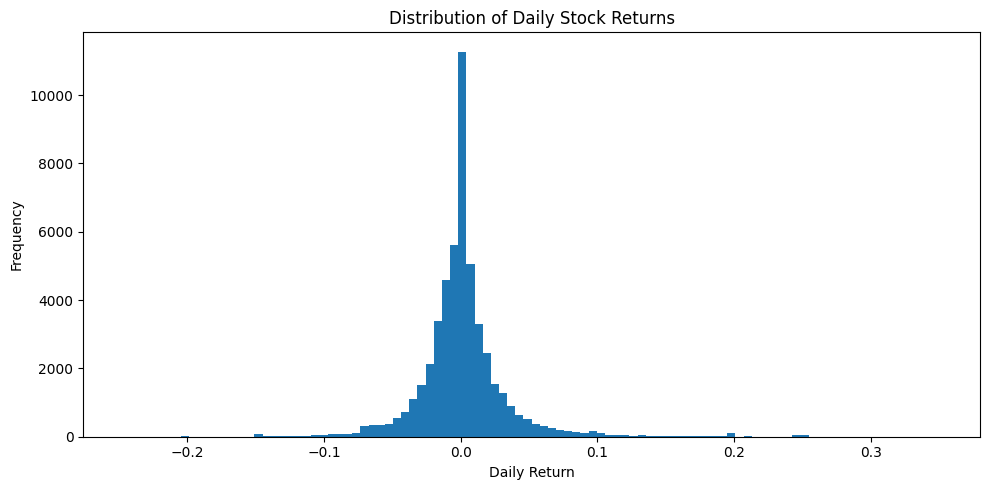

In [41]:
# Distribusi return harian
daily_returns.stack().dropna().plot(
    kind="hist", bins=100, figsize=(10, 5)
)
plt.title("Distribution of Daily Stock Returns")
plt.xlabel("Daily Return")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

In [42]:
# Analisis tren harga saham
# Karena harga nominal saham berbeda", kita normalisasi harga awal setiap saham menjadi 100 agar pergerakannya dapat dibandingkan.

# Normalisasi harga menjadi indeks 100
normalized_prices = price_table.divide(
    price_table.apply(
        lambda s: s.dropna().iloc[0] if s.notna().any() else np.nan
    ),
    axis=1
) * 100

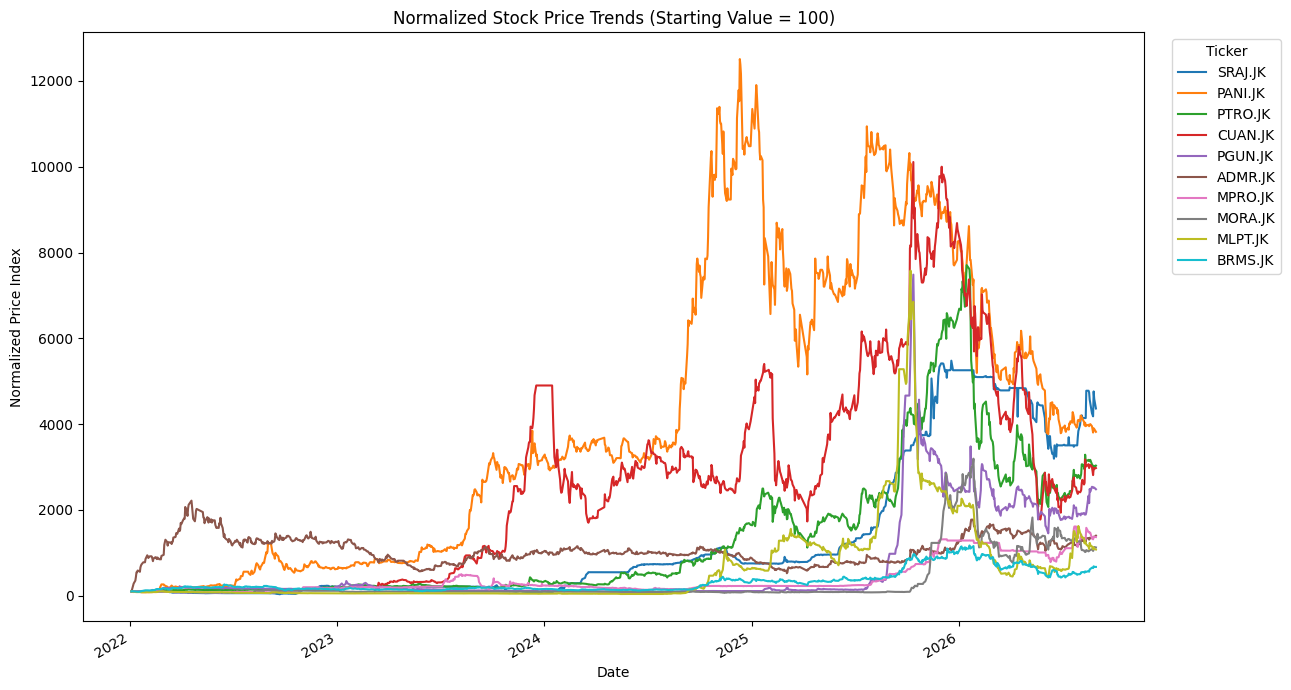

In [43]:
# Tampilkan 10 saham dengan total return tertinggi
top_tickers = summary.nlargest(10, "total_return").index

normalized_prices[top_tickers].plot(
    figsize=(13, 7)
)

plt.title("Normalized Stock Price Trends (Starting Value = 100)")
plt.xlabel("Date")
plt.ylabel("Normalized Price Index")
plt.legend(title="Ticker", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

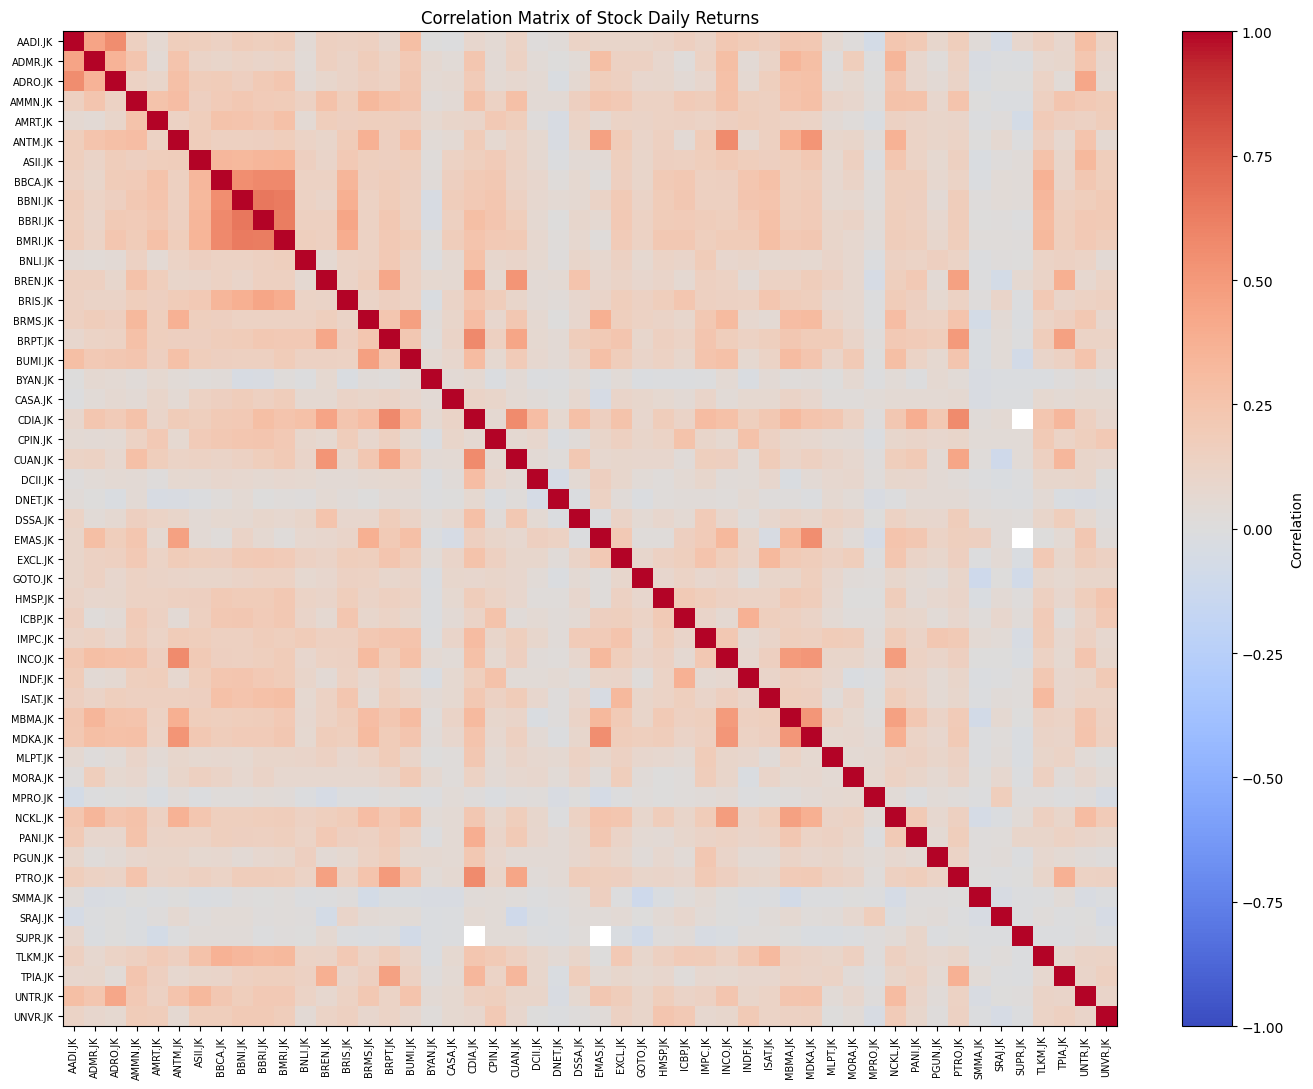

In [44]:
# Correlation matrix
correlation = daily_returns.corr(min_periods=60)

plt.figure(figsize=(14, 11))
plt.imshow(
    correlation,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    aspect="auto"
)
plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=90,
    fontsize=7
)
plt.yticks(
    range(len(correlation.index)),
    correlation.index,
    fontsize=7
)

plt.title("Correlation Matrix of Stock Daily Returns")
plt.tight_layout()
plt.show()

In [45]:
# Cari pasangan saham yang berkorelasi tinggi/rendah
upper_triangle = correlation.where(
    np.triu(np.ones(correlation.shape), k=1).astype(bool)
)

pairs = upper_triangle.stack().sort_values()

print("10 pasangan dengan korelasi terendah:")
print(pairs.head(10).round(3))

print("\n10 pasangan dengan korelasi tertinggi:")
print(pairs.tail(10).sort_values(ascending=False).round(3))

correlation.to_csv("correlation_matrix.csv")

10 pasangan dengan korelasi terendah:
ticker   ticker 
GOTO.JK  SMMA.JK   -0.102
CUAN.JK  SRAJ.JK   -0.096
GOTO.JK  SUPR.JK   -0.082
BUMI.JK  SUPR.JK   -0.075
MBMA.JK  SMMA.JK   -0.072
BRMS.JK  SMMA.JK   -0.069
AADI.JK  MPRO.JK   -0.068
BREN.JK  SRAJ.JK   -0.068
AMRT.JK  SUPR.JK   -0.063
DCII.JK  DNET.JK   -0.060
dtype: float64

10 pasangan dengan korelasi tertinggi:
ticker   ticker 
BBNI.JK  BBRI.JK    0.653
         BMRI.JK    0.640
BBRI.JK  BMRI.JK    0.625
BRPT.JK  CDIA.JK    0.574
BBCA.JK  BBRI.JK    0.573
         BMRI.JK    0.573
CDIA.JK  PTRO.JK    0.566
ANTM.JK  INCO.JK    0.565
CDIA.JK  CUAN.JK    0.565
AADI.JK  ADRO.JK    0.555
dtype: float64


10 saham berdasarkan rata-rata volume harian:
         average_daily_volume  median_daily_volume   total_volume  \
ticker                                                              
GOTO.JK          3.349783e+09         2.412801e+09  3500522856200   
BUMI.JK          2.139241e+09         9.694872e+08  2378835506600   
BRMS.JK          5.100020e+08         3.504448e+08   567122200600   
CUAN.JK          2.157605e+08         1.171545e+08   176923607200   
BBRI.JK          2.032233e+08         1.731800e+08   225984283100   
CDIA.JK          1.695932e+08         1.067622e+08    46638125000   
MBMA.JK          1.580946e+08         8.964915e+07   125527136800   
BRPT.JK          1.330562e+08         8.845045e+07   147958467570   
BMRI.JK          1.305077e+08         1.074692e+08   145124532600   
TLKM.JK          1.142034e+08         9.540070e+07   126994178100   

         trading_days  
ticker                 
GOTO.JK          1045  
BUMI.JK          1112  
BRMS.JK          1112  
CUAN.

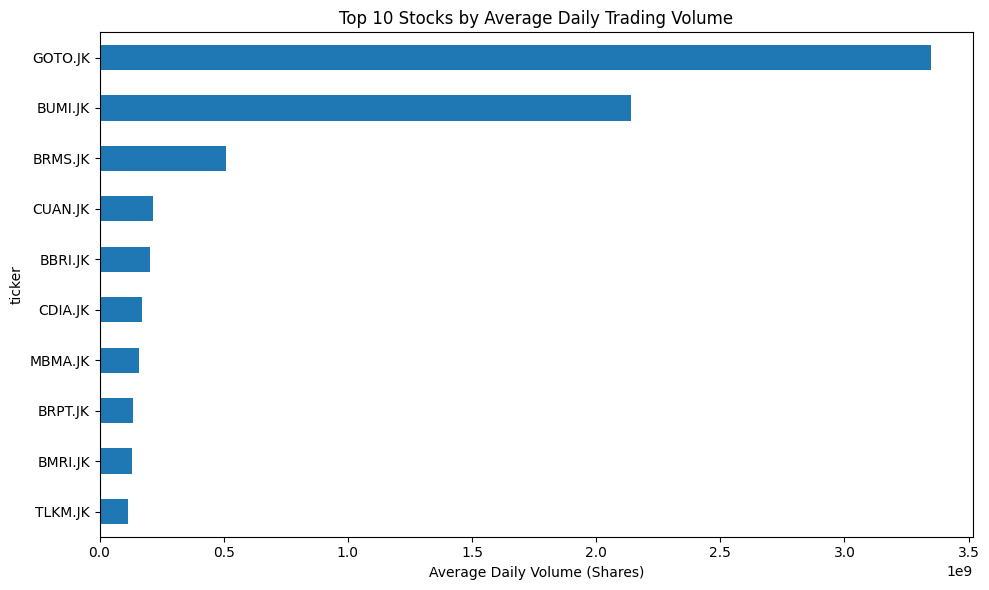

In [46]:
# Volume perdagangan per saham
volume_summary = prices.groupby("ticker").agg(
    average_daily_volume=("volume", "mean"),
    median_daily_volume=("volume", "median"),
    total_volume=("volume", "sum"),
    trading_days=("volume", "count")
).sort_values("average_daily_volume", ascending=False)

print("10 saham berdasarkan rata-rata volume harian:")
print(volume_summary.head(10).round(2))

volume_summary.head(10)["average_daily_volume"].sort_values().plot(
    kind="barh", figsize=(10, 6)
)

plt.title("Top 10 Stocks by Average Daily Trading Volume")
plt.xlabel("Average Daily Volume (Shares)")
plt.tight_layout()
plt.show()

volume_summary.to_csv("volume_summary.csv")

In [47]:
# RINGKASAN TEMUAN DESCRIPTIVE ANALYTICS

# 1. Return tertinggi dan terendah
print("=== RETURN TERTINGGI ===")
print(
    summary.nlargest(5, "annualized_return")[
        ["annualized_return", "annualized_volatility",
         "CAGR", "max_drawdown"]
    ].round(4)
)

print("\n=== TOTAL RETURN TERENDAH ===")
print(
    summary.nsmallest(5, "total_return")[
        ["total_return", "annualized_volatility",
         "CAGR", "max_drawdown"]
    ].round(4)
)

# 2. Volatilitas tertinggi
print("\n=== VOLATILITAS TERTINGGI ===")
print(
    summary.nlargest(5, "annualized_volatility")[
        ["annualized_return", "annualized_volatility",
         "max_drawdown"]
    ].round(4)
)

# 3. Drawdown terdalam
print("\n=== MAX DRAWDOWN TERDALAM ===")
print(
    summary.nsmallest(5, "max_drawdown")[
        ["total_return", "annualized_volatility",
         "max_drawdown"]
    ].round(4)
)

# 4. Pasangan saham dengan korelasi tertinggi/terendah
upper_triangle = correlation.where(
    np.triu(np.ones(correlation.shape), k=1).astype(bool)
)

correlation_pairs = upper_triangle.stack().sort_values()

print("\n=== 10 PASANGAN KORELASI TERTINGGI ===")
print(correlation_pairs.tail(10).sort_values(ascending=False).round(3))

print("\n=== 10 PASANGAN KORELASI TERENDAH ===")
print(correlation_pairs.head(10).round(3))

# 5. Saham dengan aktivitas perdagangan terendah
print("\n=== AKTIVITAS PERDAGANGAN TERENDAH ===")
print(
    volume_summary.sort_values("average_daily_volume").head(10).round(2)
)

=== RETURN TERTINGGI ===
         annualized_return  annualized_volatility    CAGR  max_drawdown
ticker                                                                 
CUAN.JK             1.4796                 0.9478  1.6490       -0.8245
EMAS.JK             1.3924                 0.7569  1.8505       -0.4278
CDIA.JK             1.3852                 1.0316  1.3188       -0.7567
PANI.JK             1.1087                 0.7653  1.1862       -0.6988
PGUN.JK             1.0710                 0.8528  0.9927       -0.8059

=== TOTAL RETURN TERENDAH ===
         total_return  annualized_volatility    CAGR  max_drawdown
ticker                                                            
GOTO.JK       -0.8691                 0.6036 -0.3708       -0.8762
UNVR.JK       -0.4680                 0.4149 -0.1267       -0.7930
CPIN.JK       -0.4396                 0.3387 -0.1169       -0.4924
MBMA.JK       -0.3785                 0.6504 -0.1316       -0.7398
MDKA.JK       -0.2686                 

In [48]:
# QUALITY CONTROL REPORT
quality_prices = prices.sort_values(
    ["ticker", "date"]
).copy()

quality_prices["previous_price"] = (
    quality_prices.groupby("ticker")["adjusted_close"].shift(1)
)

quality_prices["price_unchanged"] = (
    quality_prices["adjusted_close"].eq(
        quality_prices["previous_price"]
    )
)

quality_report = (
    quality_prices.groupby("ticker")
    .agg(
        total_observations=("adjusted_close", "count"),
        zero_volume_days=("volume", lambda x: x.eq(0).sum()),
        unchanged_price_days=("price_unchanged", "sum"),
        unique_prices=("adjusted_close", "nunique")
    )
)

quality_report["zero_volume_pct"] = (
    quality_report["zero_volume_days"]
    / quality_report["total_observations"] * 100
)

quality_report["unchanged_price_pct"] = (
    quality_report["unchanged_price_days"]
    / (quality_report["total_observations"] - 1).clip(lower=1)
    * 100
)

# Penanda untuk pemeriksaan lebih lanjut, bukan keputusan menghapus
quality_report["review_flag"] = (
    (quality_report["zero_volume_pct"] >= 10)
    | (quality_report["unchanged_price_pct"] >= 30)
)

quality_report = quality_report.sort_values(
    ["review_flag", "zero_volume_pct"],
    ascending=[False, False]
)

print(quality_report.round(2).to_string())

quality_report.to_csv("data_quality_report.csv")

         total_observations  zero_volume_days  unchanged_price_days  unique_prices  zero_volume_pct  unchanged_price_pct  review_flag
ticker                                                                                                                               
SUPR.JK                1112               970                  1022             85            87.23                91.99         True
SMMA.JK                1112               309                   737            187            27.79                66.34         True
DSSA.JK                1112               301                   432            565            27.07                38.88         True
MPRO.JK                1112               189                   414            343            17.00                37.26         True
DCII.JK                1112               145                   387            519            13.04                34.83         True
PGUN.JK                1112               137                 

# Predictive Analytics

## Mendefinisikan data range

In [49]:
# Training diambil dari target dates hingga 2024
# validation menggunakan next-day returns selama 2025 
# Untuk hasil akhir forecast mengambil next-day returns selama 2026 

MIN_HISTORY = 300
MIN_TRAIN_ROWS = 200
MIN_VALIDATION_ROWS = 20

train_start = pd.Timestamp("2022-01-01")
train_end = pd.Timestamp("2024-12-31")

validation_start = pd.Timestamp("2025-01-01")
validation_end = pd.Timestamp("2025-12-31")

final_train_start = pd.Timestamp("2022-01-01")
final_train_end = pd.Timestamp("2025-12-31")

final_test_start = pd.Timestamp("2026-01-01")
final_test_end = pd.Timestamp("2026-08-31")

feature_cols = ["lag_1", "lag_2", "lag_5", "mean_5", "vol_5"]

**Purpose**
* Through Dec 31, 2024: Train the initial models
* Jan 1-Dec 31, 2025:	Validate and compare model performance
* Through Dec 31, 2025:	Train the final Linear Regression model
* Jan 1-Aug 31, 2026: Generate final-period predictions and compare them with actual returns

## membuat fitur2 dan target kolom

In [50]:
stock_data = {}
eligibility_records = []

for ticker in daily_returns.columns:
    s = daily_returns[ticker].sort_index().astype(float)

    # memastikan tanggalnya berurutan dan tidak ada yang ter-duplikasi
    if not s.index.is_unique:
        print(f"Warning: {ticker} has duplicate dates.")
        s = s.loc[~s.index.duplicated(keep="last")]

    valid_count = int(s.notna().sum())

    if valid_count < MIN_HISTORY:
        eligibility_records.append({
            "ticker": ticker,
            "valid_returns": valid_count,
            "train_rows": 0,
            "validation_rows": 0,
            "final_test_rows": 0,
            "status": "Skipped: insufficient history"
        })
        print(
            f"Skipping {ticker}: only {valid_count} "
            "valid return observations."
        )
        continue

    data = pd.DataFrame(index=s.index)

    data["lag_1"] = s
    data["lag_2"] = s.shift(1)
    data["lag_5"] = s.shift(4)

    data["mean_5"] = s.rolling(
        window=5,
        min_periods=5
    ).mean()

    data["vol_5"] = s.rolling(
        window=5,
        min_periods=5
    ).std()

    data["target"] = s.shift(-1)

    data["target_date"] = pd.Series(
        s.index,
        index=s.index
    ).shift(-1)

    data = data.dropna(
        subset=feature_cols + ["target", "target_date"]
    ).copy()

    data["target_date"] = pd.to_datetime(data["target_date"])

    # split train, test, dan validation data
    train = data[
        data["target_date"].between(train_start, train_end)
    ]

    valid = data[
        data["target_date"].between(
            validation_start, validation_end
        )
    ]

    final_test = data[
        data["target_date"].between(
            final_test_start, final_test_end
        )
    ]

    if len(train) < MIN_TRAIN_ROWS:
        status = "Skipped: insufficient training rows"
    elif len(valid) < MIN_VALIDATION_ROWS:
        status = "Skipped: insufficient validation rows"
    else:
        status = "Eligible"

    stock_data[ticker] = data

    eligibility_records.append({
        "ticker": ticker,
        "valid_returns": valid_count,
        "usable_rows": len(data),
        "train_rows": len(train),
        "validation_rows": len(valid),
        "final_train_rows": int(
            (data["target_date"] <= final_train_end).sum()
        ),
        "final_test_rows": len(final_test),
        "status": status
    })

eligibility_report = pd.DataFrame(eligibility_records)

print("Stocks prepared:", len(stock_data))
display(eligibility_report)

Skipping CDIA.JK: only 274 valid return observations.
Skipping EMAS.JK: only 222 valid return observations.
Stocks prepared: 48


,ticker,valid_returns,usable_rows,train_rows,validation_rows,final_train_rows,final_test_rows,status
0,AADI.JK,405,400.0,10,236,246.0,154,Skipped: insufficient training rows
1,ADMR.JK,1111,1106.0,716,236,952.0,154,Eligible
2,ADRO.JK,1111,1106.0,716,236,952.0,154,Eligible
3,AMMN.JK,747,742.0,352,236,588.0,154,Eligible
4,AMRT.JK,1111,1106.0,716,236,952.0,154,Eligible
5,ANTM.JK,1111,1106.0,716,236,952.0,154,Eligible
6,ASII.JK,1111,1106.0,716,236,952.0,154,Eligible
7,BBCA.JK,1111,1106.0,716,236,952.0,154,Eligible
8,BBNI.JK,1111,1106.0,716,236,952.0,154,Eligible
9,BBRI.JK,1111,1106.0,716,236,952.0,154,Eligible


This loop process is to check one stock at a time, processing each ticker separately rather than all stocks as one continuous time series:
* `daily_returns` contains the daily percentage returns calculated in the descriptive analytics section.
* `daily_returns.columns` contains the stock tickers.
* dropna() removes missing returns, while sort_index() puts observations in chronological order.

If the ticker has fewer than 300 valid return observations, it will be skipped to avoid fitting models to very short histories.

## Training dan membandingkan 4 model

In [51]:
validation_prediction_frames = []
training_records = []

for ticker, data in stock_data.items():
    # Split by target date
    train = data[
        data["target_date"].between(train_start, train_end)
    ]

    valid = data[
        data["target_date"].between(
            validation_start, validation_end
        )
    ]

    if (
        len(train) < MIN_TRAIN_ROWS
        or len(valid) < MIN_VALIDATION_ROWS
    ):
        print(
            f"Skipping {ticker}: "
            f"train={len(train)}, validation={len(valid)}"
        )
        continue

    X_train = train[feature_cols]
    y_train = train["target"]

    X_valid = valid[feature_cols]
    y_valid = valid["target"]

    # Model 1: Zero Return Baseline
    zero_pred = np.zeros(len(valid))

    # Model 2: Historical Mean Baseline
    mean_pred = np.full(len(valid), y_train.mean())

    # Model 3: Linear Regression
    linear_model = LinearRegression()

    start_time = time.perf_counter()
    linear_model.fit(X_train, y_train)
    linear_pred = linear_model.predict(X_valid)
    linear_time = time.perf_counter() - start_time

    # Model 4: Random Forest
    rf_model = RandomForestRegressor(
        n_estimators=150,
        max_depth=5,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    )

    start_time = time.perf_counter()
    rf_model.fit(X_train, y_train)
    rf_pred = rf_model.predict(X_valid)
    rf_time = time.perf_counter() - start_time

    model_outputs = [
        ("Zero Return Baseline", zero_pred),
        ("Historical Mean Baseline", mean_pred),
        ("Linear Regression", linear_pred),
        ("Random Forest", rf_pred)
    ]

    for model_name, predicted in model_outputs:

        validation_prediction_frames.append(
            pd.DataFrame({
                "ticker": ticker,
                "date": valid["target_date"].to_numpy(),
                "actual_return": y_valid.to_numpy(),
                "predicted_return": predicted,
                "model": model_name
            })
        )

    training_records.extend([
        {
            "ticker": ticker,
            "model": "Linear Regression",
            "train_rows": len(train),
            "validation_rows": len(valid),
            "fit_predict_seconds": linear_time
        },
        {
            "ticker": ticker,
            "model": "Random Forest",
            "train_rows": len(train),
            "validation_rows": len(valid),
            "fit_predict_seconds": rf_time
        }
    ])

Skipping AADI.JK: train=10, validation=236


Trains the models using data through 2024 and evaluates their predictions on 2025 observations.

## Combine Predictions

In [52]:
if not validation_prediction_frames:
    raise ValueError(
        "No validation predictions were generated. "
        "Check data availability and split requirements."
    )

validation_predictions = pd.concat(
    validation_prediction_frames,
    ignore_index=True
)

# Keep Linear Regression predictions for downstream analysis
predictions = validation_predictions[
    validation_predictions["model"] == "Linear Regression"
].copy()

training_report = pd.DataFrame(training_records)

print("Validation prediction rows:", len(validation_predictions))
print("Eligible tickers:", predictions["ticker"].nunique())

display(training_report.head())
display(validation_predictions.head())

Validation prediction rows: 44368
Eligible tickers: 47


,ticker,model,train_rows,validation_rows,fit_predict_seconds
0,ADMR.JK,Linear Regression,716,236,0.031984
1,ADMR.JK,Random Forest,716,236,0.328396
2,ADRO.JK,Linear Regression,716,236,0.002967
3,ADRO.JK,Random Forest,716,236,0.328025
4,AMMN.JK,Linear Regression,352,236,0.002847


,ticker,date,actual_return,predicted_return,model
0,ADMR.JK,2025-01-02,-0.029167,0.0,Zero Return Baseline
1,ADMR.JK,2025-01-03,-0.030043,0.0,Zero Return Baseline
2,ADMR.JK,2025-01-06,-0.022124,0.0,Zero Return Baseline
3,ADMR.JK,2025-01-07,-0.022624,0.0,Zero Return Baseline
4,ADMR.JK,2025-01-08,-0.027778,0.0,Zero Return Baseline


The validation process evaluated four models across 47 eligible stocks, producing 44,368 prediction rows. Each stock has its own training and validation data, allowing model performance to be compared across different stocks. The zero-return baseline predicts no price movement, providing a simple benchmark against which Linear Regression and Random Forest can be evaluated. Final conclusions about model effectiveness should be based on the MAE, RMSE, and directional accuracy results.

## Evaluation

In [53]:
def regression_metrics(group):
    actual = group["actual_return"].to_numpy(dtype=float)
    predicted = group["predicted_return"].to_numpy(dtype=float)

    # Remove invalid observations
    valid = np.isfinite(actual) & np.isfinite(predicted)

    actual = actual[valid]
    predicted = predicted[valid]

    if len(actual) == 0:
        return pd.Series({
            "MAE": np.nan,
            "RMSE": np.nan,
            "Directional Accuracy": np.nan,
            "Actual Movement Rate": np.nan,
            "Prediction Coverage": np.nan,
            "Nonzero Directional Accuracy": np.nan,
            "Number of Predictions": 0
        })

    # Standard regression metrics
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    # Overall sign agreement.
    # A zero prediction matches an actual zero return.
    directional_accuracy = np.mean(
        np.sign(actual) == np.sign(predicted)
    )

    actual_moves = actual != 0
    predicted_moves = predicted != 0

    actual_movement_rate = actual_moves.mean()
    prediction_coverage = predicted_moves.mean()

    # Evaluasi arah ketika kedua nilainya selain 0 
    eligible = actual_moves & predicted_moves

    if eligible.any():
        nonzero_directional_accuracy = np.mean(
            np.sign(actual[eligible])
            == np.sign(predicted[eligible])
        )
    else:
        nonzero_directional_accuracy = np.nan

    return pd.Series({
        "MAE": mae,
        "RMSE": rmse,
        "Directional Accuracy": directional_accuracy,
        "Actual Movement Rate": actual_movement_rate,
        "Prediction Coverage": prediction_coverage,
        "Nonzero Directional Accuracy": nonzero_directional_accuracy,
        "Number of Predictions": len(actual)
    })

model_comparison = (
    validation_predictions
    .groupby("model")[
        ["actual_return", "predicted_return"]
    ]
    .apply(regression_metrics)
    .sort_values("MAE")
)

print("Model Comparison, 2025 Validation Period")
display(model_comparison.round(6))

linear_metrics = (
    predictions
    .groupby("ticker")[
        ["actual_return", "predicted_return"]
    ]
    .apply(regression_metrics)
    .sort_values("MAE")
)

print("Linear Regression Performance by Stock")
display(linear_metrics.round(6))

ticker_model_comparison = (
    validation_predictions
    .groupby(["ticker", "model"])[
        ["actual_return", "predicted_return"]
    ]
    .apply(regression_metrics)
    .reset_index()
)

print("Model Performance by Stock")
display(
    ticker_model_comparison.sort_values(
        ["ticker", "MAE"]
    ).round(6)
)

# MAE comparison table
ticker_mae_table = ticker_model_comparison.pivot(
    index="ticker",
    columns="model",
    values="MAE"
)

print("MAE Comparison by Stock")
display(ticker_mae_table.round(6))

# Equal-weighted average of stock-level metrics
equal_weight_metrics = (
    ticker_model_comparison
    .groupby("model")[
        ["MAE", "RMSE", "Directional Accuracy"]
    ]
    .mean()
    .sort_values("MAE")
)

print("Equal-Weighted Average Across Stocks 2025")
display(equal_weight_metrics.round(6))

# best model dengan nilai MAE terendah
best_model_name = equal_weight_metrics["MAE"].idxmin()

print("Selected final model:", best_model_name)
print("Selection criterion: Lowest equal-weighted MAE")

Model Comparison, 2025 Validation Period


,MAE,RMSE,Directional Accuracy,Actual Movement Rate,Prediction Coverage,Nonzero Directional Accuracy,Number of Predictions
model,,,,,,,
Zero Return Baseline,0.022704,0.038404,0.143527,0.856473,0.0,NaN,11092.0
Historical Mean Baseline,0.022977,0.038370,0.427786,0.856473,1.0,0.499474,11092.0
Random Forest,0.023425,0.038731,0.432023,0.856473,1.0,0.504421,11092.0
Linear Regression,0.023435,0.038892,0.430941,0.856473,1.0,0.503158,11092.0


Linear Regression Performance by Stock


,MAE,RMSE,Directional Accuracy,Actual Movement Rate,Prediction Coverage,Nonzero Directional Accuracy,Number of Predictions
ticker,,,,,,,
SUPR.JK,0.000078,0.000087,0.000000,0.004237,1.0,0.000000,236.0
BYAN.JK,0.008133,0.019134,0.334746,0.813559,1.0,0.411458,236.0
DNET.JK,0.012404,0.017955,0.351695,0.868644,1.0,0.404878,236.0
ASII.JK,0.013446,0.018668,0.525424,0.902542,1.0,0.582160,236.0
BBCA.JK,0.013501,0.018384,0.504237,0.919492,1.0,0.548387,236.0
SMMA.JK,0.013530,0.030322,0.313559,0.546610,1.0,0.573643,236.0
ICBP.JK,0.014004,0.018618,0.504237,0.940678,1.0,0.536036,236.0
UNTR.JK,0.014220,0.021167,0.576271,0.957627,1.0,0.601770,236.0
INDF.JK,0.014354,0.018789,0.470339,0.894068,1.0,0.526066,236.0


Model Performance by Stock


...

MAE Comparison by Stock


model,Historical Mean Baseline,Linear Regression,Random Forest,Zero Return Baseline
ticker,,,,
ADMR.JK,0.025125,0.026373,0.025702,0.024784
ADRO.JK,0.018257,0.018402,0.018669,0.017953
AMMN.JK,0.028471,0.028696,0.028305,0.028107
AMRT.JK,0.021210,0.021645,0.022055,0.020994
ANTM.JK,0.024778,0.025272,0.025601,0.024773
ASII.JK,0.013620,0.013446,0.013491,0.013608
BBCA.JK,0.013480,0.013501,0.013784,0.013391
BBNI.JK,0.017166,0.017370,0.017188,0.017048
BBRI.JK,0.016565,0.017019,0.017143,0.016535


Equal-Weighted Average Across Stocks 2025


,MAE,RMSE,Directional Accuracy
model,,,
Zero Return Baseline,0.022704,0.035179,0.143527
Historical Mean Baseline,0.022977,0.035198,0.427786
Random Forest,0.023425,0.035566,0.432023
Linear Regression,0.023435,0.035600,0.430941


Selected final model: Zero Return Baseline
Selection criterion: Lowest equal-weighted MAE


**Interpretation:**
* The zero-return baseline achieved the lowest overall MAE (0.022704), while the historical mean baseline achieved the lowest RMSE (0.038370).
* Random Forest had the highest directional accuracy among the four approaches at approximately 43.20%, but its prediction errors were higher than those of the simpler baselines. Linear Regression performed similarly but did not outperform the baselines overall.

Performance also varied across stocks, suggesting that a single model may not be suitable for every ticker. SUPR.JK requires special attention because its unusually low prediction errors are likely influenced by its high proportion of zero returns.

Overall, the tested machine learning models did not demonstrate a clear improvement over simple baselines during the 2025 validation period.

## SUPR.JK's zero returns check

In [54]:
# Check SUPR.JK's daily returns
supr_returns = daily_returns["SUPR.JK"].dropna()

print("Observations:", len(supr_returns))
print("Zero returns (%):", (supr_returns == 0).mean() * 100)
print("Unique returns:", supr_returns.nunique())
print("Standard deviation:", supr_returns.std())

# Check the original adjusted closing prices
supr_prices = price_table["SUPR.JK"].dropna().sort_index()

print(
    "\nUnchanged consecutive prices (%):",
    supr_prices.pct_change().dropna().eq(0).mean() * 100
)

display(supr_prices.head(10))

Observations: 1111
Zero returns (%): 91.98919891989199
Unique returns: 87
Standard deviation: 0.024335607363297523

Unchanged consecutive prices (%): 91.98919891989199


date
2022-01-03    15600.0
2022-01-04    15600.0
2022-01-05    15600.0
2022-01-06    15600.0
2022-01-07    15600.0
2022-01-10    15600.0
2022-01-11    15800.0
2022-01-12    16025.0
2022-01-13    16000.0
2022-01-14    16000.0
Name: SUPR.JK, dtype: float64

The results suggest that SUPR.JK has many unchanged closing prices.
* 91.99% zero returns: The adjusted closing price did not change between consecutive observations for almost 92% of the rows.
* 87 unique returns: The stock price did change occasionally, so the data is not completely constant.
* Standard deviation = 0.0243: Returns still show some variation when price changes occur.
* Example: The price stayed at 15,600 from January 3-10, 2022, before increasing to 15,800 on January 11.

This pattern indicates limited observed price movement during the study period and may affect the reliability of model evaluation.

## Generate 2026 predictions

In [55]:
final_prediction_frames = []
final_training_records = []

# Use only tickers evaluated during the 2025 validation period
eligible_tickers = set(
    validation_predictions["ticker"].unique()
)

for ticker in sorted(eligible_tickers):
    data = stock_data[ticker]

    # Final training data: target dates from 2022 through 2025
    final_train = data[
        data["target_date"].between(
            final_train_start,
            final_train_end
        )
    ].copy()

    # Final testing data: target dates from January to August 2026
    final_test = data[
        data["target_date"].between(
            final_test_start,
            final_test_end
        )
    ].copy()

    # Skip tickers with insufficient training or testing data
    if (
        len(final_train) < MIN_TRAIN_ROWS
        or len(final_test) == 0
    ):
        print(
            f"Skipping {ticker}: "
            f"train={len(final_train)}, "
            f"test={len(final_test)}"
        )
        continue

    # Prepare features and target
    X_train_final = final_train[feature_cols]
    y_train_final = final_train["target"]

    X_test_final = final_test[feature_cols]

    # Generate predictions using the model selected on 2025 validation
    if best_model_name == "Zero Return Baseline":
        final_pred = np.zeros(len(final_test))

    elif best_model_name == "Historical Mean Baseline":
        final_pred = np.full(
            len(final_test),
            y_train_final.mean()
        )

    elif best_model_name == "Linear Regression":
        final_model = LinearRegression()

        final_model.fit(
            X_train_final,
            y_train_final
        )

        final_pred = final_model.predict(
            X_test_final
        )

    elif best_model_name == "Random Forest":
        final_model = RandomForestRegressor(
            n_estimators=150,
            max_depth=5,
            min_samples_leaf=10,
            random_state=42,
            n_jobs=-1
        )

        final_model.fit(
            X_train_final,
            y_train_final
        )

        final_pred = final_model.predict(
            X_test_final
        )

    else:
        raise ValueError(
            f"Unknown selected model: {best_model_name}"
        )

    # Store predictions and actual returns for final evaluation
    final_prediction_frames.append(
        pd.DataFrame({
            "ticker": ticker,
            "feature_date": final_test.index,
            "date": final_test["target_date"].to_numpy(),
            "actual_return": final_test["target"].to_numpy(),
            "predicted_return": final_pred,
            "model": best_model_name
        })
    )

    # Record training and testing coverage
    final_training_records.append({
        "ticker": ticker,
        "selected_model": best_model_name,
        "training_rows": len(final_train),
        "testing_rows": len(final_test),
        "training_start": final_train["target_date"].min(),
        "training_end": final_train["target_date"].max(),
        "testing_start": final_test["target_date"].min(),
        "testing_end": final_test["target_date"].max()
    })


# Combine final testing predictions
if final_prediction_frames:

    predictions_2026 = pd.concat(
        final_prediction_frames,
        ignore_index=True
    )

    predictions_2026 = predictions_2026.sort_values(
        ["ticker", "date"]
    ).reset_index(drop=True)

else:

    predictions_2026 = pd.DataFrame(
        columns=[
            "ticker",
            "feature_date",
            "date",
            "actual_return",
            "predicted_return",
            "model"
        ]
    )


# Create the final training report
final_training_report = pd.DataFrame(
    final_training_records
)

# Summary
print("=" * 55)
print("FINAL TESTING - JANUARY TO AUGUST 2026")
print("=" * 55)

print("Selected model:", best_model_name)
print("Tickers evaluated:", predictions_2026["ticker"].nunique())
print("Total prediction rows:", len(predictions_2026))

if not predictions_2026.empty:
    print(
        "Testing date range:",
        predictions_2026["date"].min(),
        "to",
        predictions_2026["date"].max()
    )

    display(predictions_2026.head(10))
    display(final_training_report)

else:
    print(
        "No predictions were generated."
    )

FINAL TESTING - JANUARY TO AUGUST 2026
Selected model: Zero Return Baseline
Tickers evaluated: 47
Total prediction rows: 7238
Testing date range: 2026-01-02 00:00:00 to 2026-08-31 00:00:00


,ticker,feature_date,date,actual_return,predicted_return,model
0,ADMR.JK,2025-12-30,2026-01-02,0.054487,0.0,Zero Return Baseline
1,ADMR.JK,2026-01-02,2026-01-05,0.000000,0.0,Zero Return Baseline
2,ADMR.JK,2026-01-05,2026-01-06,0.097264,0.0,Zero Return Baseline
3,ADMR.JK,2026-01-06,2026-01-07,0.027701,0.0,Zero Return Baseline
4,ADMR.JK,2026-01-07,2026-01-08,-0.078167,0.0,Zero Return Baseline
5,ADMR.JK,2026-01-08,2026-01-09,0.023392,0.0,Zero Return Baseline
6,ADMR.JK,2026-01-09,2026-01-12,0.108571,0.0,Zero Return Baseline
7,ADMR.JK,2026-01-12,2026-01-13,0.036082,0.0,Zero Return Baseline
8,ADMR.JK,2026-01-13,2026-01-14,-0.017413,0.0,Zero Return Baseline
9,ADMR.JK,2026-01-14,2026-01-15,0.002532,0.0,Zero Return Baseline


,ticker,selected_model,training_rows,testing_rows,training_start,training_end,testing_start,testing_end
0,ADMR.JK,Zero Return Baseline,952,154,2022-01-11,2025-12-30,2026-01-02,2026-08-31
1,ADRO.JK,Zero Return Baseline,952,154,2022-01-11,2025-12-30,2026-01-02,2026-08-31
2,AMMN.JK,Zero Return Baseline,588,154,2023-07-17,2025-12-30,2026-01-02,2026-08-31
3,AMRT.JK,Zero Return Baseline,952,154,2022-01-11,2025-12-30,2026-01-02,2026-08-31
4,ANTM.JK,Zero Return Baseline,952,154,2022-01-11,2025-12-30,2026-01-02,2026-08-31
5,ASII.JK,Zero Return Baseline,952,154,2022-01-11,2025-12-30,2026-01-02,2026-08-31
6,BBCA.JK,Zero Return Baseline,952,154,2022-01-11,2025-12-30,2026-01-02,2026-08-31
7,BBNI.JK,Zero Return Baseline,952,154,2022-01-11,2025-12-30,2026-01-02,2026-08-31
8,BBRI.JK,Zero Return Baseline,952,154,2022-01-11,2025-12-30,2026-01-02,2026-08-31
9,BMRI.JK,Zero Return Baseline,952,154,2022-01-11,2025-12-30,2026-01-02,2026-08-31


## Final Test Evaluation 2026

In [56]:
if predictions_2026.empty:
    print("No final testing predictions available.")

else:
    assert predictions_2026["model"].eq(
        best_model_name
    ).all() if "model" in predictions_2026.columns else True

    test_metrics = regression_metrics(predictions_2026)

    print("Final Testing Results 2026")
    print("Selected model:", best_model_name)

    display(
        test_metrics.to_frame(
            name="2026 Test Result"
        ).round(6)
    )

    # Performance by ticker
    test_metrics_by_ticker = (
        predictions_2026
        .groupby("ticker")[
            ["actual_return", "predicted_return"]
        ]
        .apply(regression_metrics)
        .sort_values("MAE")
    )

    print("2026 Performance by Stock")
    display(test_metrics_by_ticker.round(6))

Final Testing Results 2026
Selected model: Zero Return Baseline


,2026 Test Result
MAE,0.027042
RMSE,0.043092
Directional Accuracy,0.134706
Actual Movement Rate,0.865294
Prediction Coverage,0.000000
Nonzero Directional Accuracy,NaN
Number of Predictions,7238.000000


2026 Performance by Stock


,MAE,RMSE,Directional Accuracy,Actual Movement Rate,Prediction Coverage,Nonzero Directional Accuracy,Number of Predictions
ticker,,,,,,,
SUPR.JK,0.000000,0.000000,1.000000,0.000000,0.0,NaN,154.0
GOTO.JK,0.009974,0.019499,0.642857,0.357143,0.0,NaN,154.0
DNET.JK,0.010417,0.018935,0.272727,0.727273,0.0,NaN,154.0
INDF.JK,0.012838,0.017389,0.110390,0.889610,0.0,NaN,154.0
DCII.JK,0.013502,0.025144,0.292208,0.707792,0.0,NaN,154.0
SMMA.JK,0.014575,0.027206,0.311688,0.688312,0.0,NaN,154.0
ICBP.JK,0.014818,0.020274,0.097403,0.902597,0.0,NaN,154.0
BBRI.JK,0.015918,0.020857,0.051948,0.948052,0.0,NaN,154.0
SRAJ.JK,0.015974,0.035213,0.571429,0.428571,0.0,NaN,154.0


The Zero Return Baseline was selected as the best model based on the lowest equal-weighted MAE during the 2025 validation period. However, its 2026 testing results show limited predictive ability, with an MAE of 0.027042 and a directional accuracy of 13.47%. Since the model predicts zero returns for every observation, its prediction coverage is 0%, meaning it cannot capture actual market movements. These results suggest that predicting stock returns remains challenging, and the selected model may be more effective at minimizing prediction errors than capturing market direction.

## Export to CSV

In [57]:
# Export the predictive analytics outputs
validation_predictions.to_csv("model_comparison_predictions_2025.csv", index=False)
predictions.to_csv("predictions_2025.csv", index=False)

if not predictions_2026.empty:
    predictions_2026.to_csv("predictions_2026.csv", index=False)

print("Predictive analytics exports completed.")
print("Created:")
print("- model_comparison_predictions_2025.csv")
print("- predictions_2025.csv")

if not predictions_2026.empty:
    print("- predictions_2026.csv")

Predictive analytics exports completed.
Created:
- model_comparison_predictions_2025.csv
- predictions_2025.csv
- predictions_2026.csv


* model_comparison_predictions_2025.csv: Predictions from all four models, including baselines.
* predictions_2025.csv:	Only the 2025 Linear Regression predictions
* predictions_2026.csv:	2026 Linear Regression predictions and actual returns

## Sanity Check

In [58]:
# 2025 validation checks
assert not validation_predictions.empty
assert validation_predictions["actual_return"].notna().all()
assert validation_predictions["predicted_return"].notna().all()

assert validation_predictions["date"].between(
    validation_start, validation_end
).all()

# Every model should use the same number of observations
print("Prediction counts by model:")
display(
    validation_predictions.groupby("model").agg(
        prediction_rows=("actual_return", "size"),
        unique_tickers=("ticker", "nunique"),
        unique_dates=("date", "nunique")
    )
)

# Verify that all models use identical actual returns
actual_counts = (
    validation_predictions.groupby("model")["actual_return"]
    .count()
)

assert actual_counts.nunique() == 1, (
    "Models have different counts of valid actual returns."
)

# 2026 checks
if not predictions_2026.empty:

    assert predictions_2026["actual_return"].notna().all()
    assert predictions_2026["predicted_return"].notna().all()

    assert predictions_2026["date"].between(
        final_test_start, final_test_end
    ).all()

    assert not predictions_2026.duplicated(
        ["ticker", "date"]
    ).any()

    print("\n2026 forecast checks passed.")
    print(
        "2026 date range:",
        predictions_2026["date"].min(),
        "to",
        predictions_2026["date"].max()
    )

print("\nAll sanity checks passed.")

Prediction counts by model:


,prediction_rows,unique_tickers,unique_dates
model,,,
Historical Mean Baseline,11092,47,236
Linear Regression,11092,47,236
Random Forest,11092,47,236
Zero Return Baseline,11092,47,236



2026 forecast checks passed.
2026 date range: 2026-01-02 00:00:00 to 2026-08-31 00:00:00

All sanity checks passed.


# Prescriptive Analytics

# Prescriptive Analytics: Portfolio Optimization (v3)

**Portofolio utama: Blend 50% Equal Weight + 50% Risk Parity (ERC)**, dengan batas 10% per saham dan 35% per sektor.

### Mengapa v3 berbeda dari v2
Uji **walk-forward** (rebalancing bulanan, 33 bulan, biaya transaksi dihitung, hanya memakai data sampai tanggal keputusan) menunjukkan bahwa:
1. Tidak ada strategi optimasi yang mengalahkan Equal Weight secara konsisten pada Sharpe ratio.
2. **Koreksi klaim v2**: v2 menyebut prior ekuilibrium Black-Litterman "jauh lebih andal" daripada rata-rata historis. Itu hanya berlaku pada *satu* jendela uji (Jan-Agu 2026). Pada walk-forward 33 bulan, Max Sharpe dengan prior justru salah satu yang terburuk. Klaim tersebut dicabut.
3. Strategi berbasis risiko (Risk Parity dan Blend dengan Equal Weight) menurunkan volatilitas dan *drawdown* dengan penurunan return kecil, dan hasilnya lebih stabil antar-periode. Karena itu dipilih sebagai portofolio utama.

### Alur
1. Konfigurasi, universe (buang kualitas data buruk dan saham HSC), statistik deskriptif
2. Skor faktor 8 sektor dan faktor makro (dipakai pada komparator Black-Litterman)
3. Fungsi model: kovarians campuran, optimizer, simulator dengan biaya
4. Ringkasan skill model prediktif (validasi 2025)
5. **Walk-forward** semua strategi
6. **Fase B**: portofolio utama, alokasi Rp10 juta, frontier, komparator BL+view
7. **Eksperimen berlabel**: sinyal prediktif mingguan (keyakinan kecil, rebalancing terbatas), tidak masuk portofolio utama
8. Sanity check, rekomendasi, ekspor

In [ ]:
# Konfigurasi
import os, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.stats import spearmanr
from sklearn.covariance import LedoitWolf
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

KAGGLE_DIR = "/kaggle/input/datasets/cheryleugene/stok-saham"
DATA_DIR   = KAGGLE_DIR if os.path.exists(KAGGLE_DIR) else "."     # lokasi stock_master.csv

# ---- Parameter portofolio ----
TRADING_DAYS = 252
RF           = 0.0575   # BI Rate (Okt 2026) sebagai proksi risk-free
W_MAX        = 0.10     # maks bobot per saham
SECTOR_CAP   = 0.35     # maks bobot per sektor
MIN_COVERAGE = 0.95     # saham harus punya >= 95% data di window estimasi

# ---- Parameter model risiko dan return ----
EWMA_HL = 63            # half-life EWMA (hari bursa)
W_EWMA  = 0.50          # bobot EWMA dalam kovarians campuran (sisanya Ledoit-Wolf)
DELTA   = 2.5           # risk aversion untuk return ekuilibrium
TAU     = 0.05          # ketidakpastian prior Black-Litterman
SHRINK  = 0.5           # shrinkage mean historis ke rata-rata silang saham

# ---- Parameter view (hanya untuk komparator Black-Litterman) ----
SHOCKS = {"USDIDR": +0.02, "Gold": +0.03, "Oil": +0.04}   # skenario 3 bulan ke depan (EDIT sesuai asumsi)
SCENARIO_ANNUALIZER = 4.0
T_MIN      = 2.0
MAX_VIEW   = 0.10
CONF_DATA  = 0.30
CONF_SCORE = 0.40

# ---- Walk-forward ----
WF_FIRST   = pd.Timestamp("2023-12-01")   # rebalance pertama setelah data >= ~2 tahun
TUNE_END   = pd.Timestamp("2025-06-30")   # periode 1 (seleksi) vs periode 2 (konfirmasi)
COST_BUY   = 0.0015                       # biaya beli (asumsi)
COST_SELL  = 0.0025                       # biaya jual (asumsi)
TREND_MA   = 100                          # filter tren: indeks EW di bawah MA 100 hari -> eksposur 50%
TREND_EXPO = 0.5

# ---- Eksperimen sinyal mingguan (berlabel) ----
SIG_H      = 5        # horizon sinyal (hari bursa)
TILT_KAPPA = 0.15     # kekuatan tilt: bobot dasar x (1 + 0,15 x z), z dipotong +-2 -> maks +-30%
TILT_BAND  = 0.03     # rebalance mingguan hanya bila turnover target >= 3%
Z_CLIP     = 2.0

FINAL_END  = min(pd.Timestamp("2026-08-31"), daily_returns.index.max())
print("Konfigurasi dimuat. Data harga terakhir:", daily_returns.index.max().date())

## 1. Universe: buang kualitas data buruk dan saham HSC

**HSC (High Shareholding Concentration)**: emiten dengan kepemilikan sangat terkonsentrasi. BEI mengecualikannya dari perhitungan IHSG mulai 2 Nov 2026, dan MSCI sedang mengkonsultasikan penurunan status Indonesia. Risikonya: likuiditas tipis, arus keluar asing, dan volatilitas historis yang tampak rendah karena jarang diperdagangkan.

Daftar di bawah adalah 80 emiten per Okt 2026 (sumber: BEI via Bisnis.com, 20 Okt 2026). BEI menambah daftar menjadi 82 emiten setelahnya, jadi **update daftar ini secara berkala**.

In [ ]:
# Filter universe
HSC_TICKERS = {
    "SSMS","SMMT","BMAS","TBIG","CITA","PSAB","BALI","MAYA","CLAY","ADES",
    "TMAS","BBMD","INPP","SAME","DMND","EPMT","MTEL","SHIP","DUTI","BSWD",
    "INDO","BIKE","MSJA","NICK","SAFE","BDKR","MDIA","BAJA","BKDP","ALKA",
    "AGAR","BNII","MCOL","LIFE","POLU","ELPI","KING","ALII","FITT","YUPI",
    "KONI","MKPI","CMNT","SMAR","CMNP","PRAY","MPRO","BELI","MEGA","GEMS",
    "MLPT","STTP","BTPN","BBSI","SILO","FAPA","RISE","SOHO","BBHI","PGUN",
    "BINA","BNLI","SRAJ","MORA","DNET","BYAN","DCII","HATM","DGWG","SATU",
    "MGRO","TCPI","WBSA","SOTS","ROCK","RLCO","IFSH","DSSA","BREN","AGII",
}

stock_master = pd.read_csv(f"{DATA_DIR}/stock_master.csv")
stock_master["ticker"] = stock_master["ticker"].astype(str).where(
    stock_master["ticker"].astype(str).str.endswith(".JK"),
    stock_master["ticker"].astype(str) + ".JK")
MCAP = stock_master.set_index("ticker")["market_cap_m_idr"]
NAMES = stock_master.set_index("ticker")["company_name"]

all_tickers  = list(daily_returns.columns)
quality_flag = set(quality_report.index[quality_report["review_flag"]])
hsc_flag     = {t for t in all_tickers if t.replace(".JK", "") in HSC_TICKERS}
EXCLUDED     = quality_flag | hsc_flag

excl = pd.DataFrame({
    "quality_flag": [t in quality_flag for t in sorted(EXCLUDED)],
    "HSC":          [t in hsc_flag     for t in sorted(EXCLUDED)],
}, index=sorted(EXCLUDED))
print(f"Dibuang: {len(EXCLUDED)} saham  (quality-flag {len(quality_flag)}, HSC {len(hsc_flag)}, irisan {len(quality_flag & hsc_flag)})")
display(excl)


def estimation_window(end):
    """Return harian utk estimasi: tanpa fillna, saham dgn coverage >= MIN_COVERAGE, tanggal lengkap."""
    cand = [t for t in all_tickers if t not in EXCLUDED]
    est = daily_returns.loc[:end, cand]
    uni = est.columns[est.notna().mean() >= MIN_COVERAGE].tolist()
    est = est[uni].dropna()
    est = est.clip(est.quantile(0.01), est.quantile(0.99), axis=1)   # winsorize 1%-99%
    assert len(est) >= 500, "Data estimasi terlalu pendek"
    return est

_e = estimation_window(FINAL_END)
print(f"Universe akhir (s.d. {FINAL_END.date()}): {_e.shape[1]} saham, {len(_e)} hari estimasi")

## 2. Skor faktor (8 faktor, kondisi Okt 2026)

| # | Faktor | Bobot | Kondisi terkini | Saham utama |
|---|---|---|---|---|
| F1 | Batu bara | 15% | Newcastle ~US$150/ton; kuota RKAB dipangkas; permintaan China/India kuat; risiko pajak/bea keluar 2027 | ADRO, ADMR, PTRO, BUMI, UNTR |
| F2 | Logam dan emas | 10% | Emas ~US$4.150/oz; nikel LME ~US$16.600/ton; kuota nikel ketat | ANTM, INCO, MDKA, BRMS |
| F3 | Rupiah | 15% | USD/IDR ~17.985; eksportir untung, importir rugi | Tambang (+), konsumer/petrokimia (-) |
| F4 | BI Rate 5,75% | 15% | Ditahan; NIM bank terbantu, emiten ber-leverage tertekan | Bank (+), TPIA/BRPT/properti (-) |
| F5 | BUMN dan Danantara | 20% | Danantara membeli saham BUMN saat tekanan MSCI | BBRI, BMRI, BBNI, TLKM, ANTM (+) |
| F6 | Konsumen | 15% | Keyakinan konsumen melemah; inflasi 3,28% | UNVR, HMSP, ICBP, INDF, CPIN (-) |
| F7 | Telco/digital | 5% | Konsolidasi XL-Smartfren memperkuat pricing power | ISAT, EXCL (+) |
| F8 | Risiko MSCI | 5% | Konsultasi downgrade s.d. 30 Apr 2027, keputusan final 30 Jun 2027 | Semua (-, kecil) |

Skala skor: **-2** (sangat negatif) sampai **+2** (sangat positif), 0 = netral. Skor ini adalah **asumsi analis** dan harus di-review tiap kuartal.

Jika faktor makro berhasil diunduh, **F3 (Rupiah) dinonaktifkan dari skor manual** karena sudah ditangani regresi beta (menghindari hitung ganda).

In [ ]:
# Sektor dan skor faktor
SECTOR_MAP = {
    # Bank
    "BBCA.JK":"Bank","BBRI.JK":"Bank","BMRI.JK":"Bank","BBNI.JK":"Bank","BRIS.JK":"Bank","BNLI.JK":"Bank",
    # Batu bara dan energi
    "ADRO.JK":"Batu Bara","AADI.JK":"Batu Bara","BYAN.JK":"Batu Bara","BUMI.JK":"Batu Bara",
    "PTRO.JK":"Batu Bara","ADMR.JK":"Batu Bara","DSSA.JK":"Batu Bara","CUAN.JK":"Batu Bara",
    # Logam dan emas
    "ANTM.JK":"Logam & Emas","INCO.JK":"Logam & Emas","MDKA.JK":"Logam & Emas","MBMA.JK":"Logam & Emas",
    "NCKL.JK":"Logam & Emas","AMMN.JK":"Logam & Emas","BRMS.JK":"Logam & Emas","EMAS.JK":"Logam & Emas",
    # Petrokimia dan energi baru
    "TPIA.JK":"Petrokimia","BRPT.JK":"Petrokimia","BREN.JK":"Petrokimia","CDIA.JK":"Petrokimia",
    # Telco dan digital
    "TLKM.JK":"Telco & Digital","ISAT.JK":"Telco & Digital","EXCL.JK":"Telco & Digital","MORA.JK":"Telco & Digital",
    "SUPR.JK":"Telco & Digital","GOTO.JK":"Telco & Digital","DCII.JK":"Telco & Digital","MLPT.JK":"Telco & Digital",
    # Konsumer
    "UNVR.JK":"Konsumer","ICBP.JK":"Konsumer","INDF.JK":"Konsumer","HMSP.JK":"Konsumer",
    "CPIN.JK":"Konsumer","AMRT.JK":"Konsumer","DNET.JK":"Konsumer",
    # Otomotif dan industri
    "ASII.JK":"Otomotif & Industri","UNTR.JK":"Otomotif & Industri","IMPC.JK":"Otomotif & Industri","PGUN.JK":"Otomotif & Industri",
    # Properti dan keuangan lain
    "PANI.JK":"Properti & Lain","MPRO.JK":"Properti & Lain","SMMA.JK":"Properti & Lain",
    "CASA.JK":"Properti & Lain","SRAJ.JK":"Properti & Lain",
}   # klasifikasi sektor adalah perkiraan; cek ulang bila dipakai untuk keputusan nyata

FACTOR_NAMES   = ["Coal", "Metal_Emas", "Rupiah", "BI_Rate", "BUMN", "Consumer", "Digital", "MSCI_Risk"]
FACTOR_WEIGHTS = np.array([0.15, 0.10, 0.15, 0.15, 0.20, 0.15, 0.05, 0.05])
assert abs(FACTOR_WEIGHTS.sum() - 1) < 1e-9

#                  Coal  Metal Rupiah BI    BUMN  Cons  Digit MSCI
RAW_SCORES = {
    "BBCA.JK": [ 0.0,  0.0,  0.0, +1.5,  0.0,  0.0,  0.0, -0.3],
    "BBRI.JK": [ 0.0,  0.0,  0.0, +0.8, +1.5,  0.0,  0.0, -0.1],
    "BMRI.JK": [ 0.0,  0.0,  0.0, +1.0, +1.5,  0.0,  0.0, -0.1],
    "BBNI.JK": [ 0.0,  0.0,  0.0, +0.8, +1.0,  0.0,  0.0, -0.1],
    "BRIS.JK": [ 0.0,  0.0,  0.0, +0.5, +0.8,  0.0,  0.0, -0.2],
    "ADRO.JK": [+1.5,  0.0, +1.0,  0.0,  0.0,  0.0,  0.0, -0.3],
    "ADMR.JK": [+1.5, +0.5, +1.0,  0.0,  0.0,  0.0,  0.0, -0.3],
    "PTRO.JK": [+1.5,  0.0, +1.0,  0.0,  0.0,  0.0,  0.0, -0.3],
    "BUMI.JK": [+1.0,  0.0, +0.8, -0.5,  0.0,  0.0,  0.0, -0.5],
    "AADI.JK": [+1.5,  0.0, +1.0,  0.0,  0.0,  0.0,  0.0, -0.3],
    "ANTM.JK": [ 0.0, +1.5, +0.8,  0.0, +0.8,  0.0,  0.0, -0.2],
    "INCO.JK": [ 0.0, +1.0, +0.8,  0.0, +0.5,  0.0,  0.0, -0.2],
    "MDKA.JK": [ 0.0, +1.0, +0.8,  0.0,  0.0,  0.0,  0.0, -0.3],
    "BRMS.JK": [ 0.0, +1.5, +0.8,  0.0,  0.0,  0.0,  0.0, -0.3],
    "AMMN.JK": [ 0.0, +1.2, +0.8, -0.3,  0.0,  0.0,  0.0, -0.4],
    "TLKM.JK": [ 0.0,  0.0, -0.5,  0.0, +1.0,  0.0, +0.5, -0.1],
    "ISAT.JK": [ 0.0,  0.0, -0.5,  0.0,  0.0,  0.0, +1.0, -0.3],
    "EXCL.JK": [ 0.0,  0.0, -0.5,  0.0,  0.0,  0.0, +0.8, -0.3],
    "UNVR.JK": [ 0.0,  0.0, -0.5,  0.0,  0.0, -2.0,  0.0, -0.3],
    "ICBP.JK": [ 0.0,  0.0, -1.0,  0.0,  0.0, -0.5,  0.0, -0.3],
    "INDF.JK": [ 0.0,  0.0, -1.0,  0.0,  0.0, -0.5,  0.0, -0.3],
    "CPIN.JK": [ 0.0,  0.0, -0.8,  0.0,  0.0, -1.0,  0.0, -0.3],
    "AMRT.JK": [ 0.0,  0.0, -0.3,  0.0,  0.0, -0.3,  0.0, -0.3],
    "HMSP.JK": [ 0.0,  0.0, -0.5,  0.0,  0.0, -1.5,  0.0, -0.3],
    "UNTR.JK": [+0.5,  0.0,  0.0, +0.2,  0.0,  0.0,  0.0, -0.3],
    "ASII.JK": [+0.2,  0.0, -0.3,  0.0,  0.0, -0.3,  0.0, -0.3],
    "TPIA.JK": [ 0.0,  0.0, -1.0, -1.5,  0.0,  0.0,  0.0, -0.5],
    "BRPT.JK": [ 0.0,  0.0, -1.0, -1.5,  0.0,  0.0,  0.0, -0.5],
    "PANI.JK": [ 0.0,  0.0,  0.0, -0.8,  0.0, -0.2,  0.0, -0.3],
    "IMPC.JK": [ 0.0,  0.0, -0.3, -0.5,  0.0, -0.2,  0.0, -0.3],
}

## 1b. Statistik deskriptif universe
Return tahunan (rata-rata harian × 252), volatilitas tahunan (simpangan baku harian × √252), dan korelasi antar-saham pada universe akhir.

In [ ]:
# Statistik deskriptif universe
UNI = estimation_window(FINAL_END).columns.tolist()
_r = daily_returns[UNI]
desc_ret = _r.mean() * TRADING_DAYS
desc_vol = _r.std() * np.sqrt(TRADING_DAYS)
_C = estimation_window(FINAL_END).corr()
_iu = np.triu_indices(len(UNI), 1)
_same, _diff = [], []
for _a in range(len(UNI)):
    for _b in range(_a + 1, len(UNI)):
        (_same if SECTOR_MAP.get(UNI[_a]) == SECTOR_MAP.get(UNI[_b]) else _diff).append(_C.values[_a, _b])
_cv = _C.values[_iu]
_tri = np.triu(np.ones_like(_C.values), 1) > 0
_kmax = np.unravel_index(np.argmax(np.where(_tri, _C.values, -9)), _C.shape)
_kmin = np.unravel_index(np.argmin(np.where(_tri, _C.values, 9)), _C.shape)
desc_stats = {
    "n saham": len(UNI),
    "return tahunan min": desc_ret.min(), "(saham)": desc_ret.idxmin(),
    "return tahunan max": desc_ret.max(), " (saham)": desc_ret.idxmax(),
    "saham return negatif": int((desc_ret < 0).sum()),
    "vol tahunan min": desc_vol.min(), "(saham) ": desc_vol.idxmin(),
    "vol tahunan max": desc_vol.max(), "(saham)  ": desc_vol.idxmax(),
    "korelasi rata-rata": _cv.mean(), "korelasi sesektor": np.mean(_same), "korelasi lintas sektor": np.mean(_diff),
    "korelasi tertinggi": f"{UNI[_kmax[0]]} - {UNI[_kmax[1]]} ({_C.values[_kmax]:.2f})",
    "korelasi terendah": f"{UNI[_kmin[0]]} - {UNI[_kmin[1]]} ({_C.values[_kmin]:.2f})",
}
display(pd.Series(desc_stats).to_frame("nilai"))

_sec = sorted({SECTOR_MAP.get(t, "Lain-lain") for t in UNI}); _pal = dict(zip(_sec, plt.cm.tab10.colors))
fig, ax = plt.subplots(figsize=(8, 5.5))
for t in UNI:
    ax.scatter(desc_vol[t] * 100, desc_ret[t] * 100, s=28, color=_pal[SECTOR_MAP.get(t, "Lain-lain")], edgecolor="white", zorder=3)
    ax.annotate(t.replace(".JK", ""), (desc_vol[t] * 100, desc_ret[t] * 100), fontsize=7, xytext=(3, 2), textcoords="offset points")
for s_ in _sec: ax.scatter([], [], color=_pal[s_], label=s_)
ax.axhline(0, color="k", lw=0.6, ls=":"); ax.legend(ncol=2, frameon=False, fontsize=8)
ax.set_xlabel("Volatilitas tahunan (%)"); ax.set_ylabel("Rata-rata return tahunan (%)"); ax.grid(alpha=.25)
ax.set_title("Return dan risiko 28 saham universe"); plt.tight_layout(); plt.savefig("fig_risk_return.png", dpi=150); plt.show()

## 3. Faktor makro (tanpa fallback acak)

Faktor: **IHSG** (hanya variabel kontrol pasar), **USD/IDR**, **emas**, **minyak**. Emas dan minyak (pasar AS) di-lag 1 hari agar sinkron dengan jam bursa Indonesia.

Loader memakai urutan: cache lokal `macro_factors.csv` → unduh yfinance (`auto_adjust=False`). Jika keduanya gagal, **tidak ada data pengganti**; view data-driven dimatikan dan peringatan dicetak.

In [ ]:
# Loader faktor makro
MACRO_MAP = {"^JKSE": "IHSG", "IDR=X": "USDIDR", "GC=F": "Gold", "CL=F": "Oil"}
MACRO_COLS = ["IHSG", "USDIDR", "Gold", "Oil"]

def load_macro(start, end, cache="macro_factors.csv"):
    from_cache = os.path.exists(cache)
    if from_cache:
        px = pd.read_csv(cache, index_col=0, parse_dates=True)
        src = f"cache lokal ({cache})"
    else:
        try:
            import yfinance as yf
            raw = yf.download(list(MACRO_MAP), start=start, end=end + pd.Timedelta(days=1),
                              auto_adjust=False, progress=False)
            fields = raw.columns.get_level_values(0)
            px = raw["Adj Close"] if "Adj Close" in fields else raw["Close"]
            px = px.rename(columns=MACRO_MAP)
            px.index = pd.to_datetime(px.index).tz_localize(None)
            src = "yfinance"
        except Exception as e:
            print(f"[PERINGATAN] Unduh faktor makro gagal: {type(e).__name__}: {e}")
            return None, None
    # validasi: tidak boleh diam-diam salah
    if not set(MACRO_COLS).issubset(px.columns):
        print("[PERINGATAN] Kolom faktor tidak lengkap:", list(px.columns)); return None, None
    px = px[MACRO_COLS].sort_index()
    if px.dropna(how="all").shape[0] < 500 or (px.nunique() < 50).any():
        print("[PERINGATAN] Data faktor kosong/terlalu pendek/konstan; tidak dipakai.")
        if from_cache:
            print(f"   Cache {cache} tampak rusak: hapus file itu lalu jalankan ulang.")
        return None, None
    if not from_cache:
        px.to_csv(cache)          # simpan cache HANYA setelah lolos validasi
    ret = px.pct_change(fill_method=None)
    ret[["Gold", "Oil"]] = ret[["Gold", "Oil"]].shift(1)   # sinkronisasi jam bursa
    return ret.dropna(how="all"), src

macro_ret, macro_src = load_macro(daily_returns.index.min(), FINAL_END)
MACRO_OK = macro_ret is not None
if MACRO_OK:
    print(f"Faktor makro OK (sumber: {macro_src}) | {macro_ret.index.min().date()} s.d. {macro_ret.index.max().date()}")
    print(macro_ret.describe().loc[["count", "mean", "std"]].round(5))
else:
    print("\n" + "!" * 78)
    print("FAKTOR MAKRO TIDAK TERSEDIA -> view data-driven DIMATIKAN.")
    print("Portofolio tetap dihitung dgn prior ekuilibrium + skor sektor manual.")
    print("Solusi: jalankan di lingkungan dgn internet, atau letakkan macro_factors.csv (harga harian:")
    print("kolom date, IHSG, USDIDR, Gold, Oil) di folder notebook.")
    print("!" * 78)

# Skor komposit (F3 Rupiah dimatikan jika regresi makro aktif, agar tidak hitung ganda)
fw = FACTOR_WEIGHTS.copy()
if MACRO_OK:
    fw[FACTOR_NAMES.index("Rupiah")] = 0.0
    fw = fw / fw.sum()
score_df = pd.DataFrame.from_dict(RAW_SCORES, orient="index", columns=FACTOR_NAMES)
score_df["composite"] = score_df[FACTOR_NAMES].values @ fw
score_df["score_norm"] = (score_df["composite"] / 2.0).clip(-1, 1)

In [ ]:
# Heatmap skor faktor
fig, ax = plt.subplots(figsize=(10, max(6, 0.32 * len(score_df))))
hm = score_df[FACTOR_NAMES].astype(float)
im = ax.imshow(hm.values, cmap="RdYlGn", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(len(FACTOR_NAMES))); ax.set_xticklabels(FACTOR_NAMES, rotation=30, ha="right")
ax.set_yticks(range(len(hm))); ax.set_yticklabels([t.replace(".JK", "") for t in hm.index], fontsize=8)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        ax.text(j, i, f"{hm.iat[i, j]:.1f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, ax=ax, shrink=0.6, label="Skor")
ax.set_title("Skor faktor per saham (asumsi analis, Okt 2026)")
plt.tight_layout(); plt.savefig("factor_heatmap.png", dpi=130); plt.show()

## 4. Model dan optimizer

* **Kovarians** = 50% Ledoit-Wolf + 50% EWMA (half-life 63 hari). Campuran dua matriks positif-semidefinit tetap positif-definit.
* **Prior** `π = rf + δ·Σ·w_mkt` dari bobot market cap (komparator Black-Litterman).
* **Risk Parity (ERC)**: bobot yang membuat kontribusi risiko tiap saham sama, dengan batas 10% per saham dan 35% per sektor.
* **Optimizer**: SLSQP dari lima titik awal (deterministik). **Simulator**: buy-and-hold harian dengan biaya beli/jual dan opsi kas.

In [ ]:
# Fungsi model
def cov_blend(est):
    """50% Ledoit-Wolf + 50% EWMA, tahunan."""
    X = est.values
    S_lw = LedoitWolf().fit(X).covariance_ * TRADING_DAYS
    lam = 0.5 ** (1 / EWMA_HL)
    w = lam ** np.arange(len(X) - 1, -1, -1); w /= w.sum()
    xc = X - (w[:, None] * X).sum(0)
    S_ew = (xc * w[:, None]).T @ xc * TRADING_DAYS
    S = (1 - W_EWMA) * S_lw + W_EWMA * S_ew
    return pd.DataFrame((S + S.T) / 2, index=est.columns, columns=est.columns)

def cov_lw(est):
    return pd.DataFrame(LedoitWolf().fit(est.values).covariance_ * TRADING_DAYS,
                        index=est.columns, columns=est.columns)

def mu_hist_shrunk(est):
    raw = est.mean() * TRADING_DAYS
    return (1 - SHRINK) * raw + SHRINK * raw.mean()

def equilibrium_prior(S):
    cap = MCAP.reindex(S.index)
    cap = cap.fillna(cap.median())
    w_m = cap / cap.sum()
    pi = RF + DELTA * (S.values @ w_m.values)
    return pd.Series(pi, index=S.index), w_m

def factor_betas(est, macro_ret):
    """OLS: return saham ~ IHSG + USDIDR + Gold + Oil. Mengembalikan beta dan t-stat."""
    Xm = macro_ret[MACRO_COLS].reindex(est.index).dropna()
    assert len(Xm) >= 300, "Irisan tanggal saham-faktor terlalu sedikit"
    X = np.column_stack([np.ones(len(Xm)), Xm.values])
    XtX_inv = np.linalg.inv(X.T @ X)
    B, T = {}, {}
    for t in est.columns:
        y = est.loc[Xm.index, t].values
        b = XtX_inv @ X.T @ y
        e = y - X @ b
        se = np.sqrt(np.diag(XtX_inv) * (e @ e) / (len(y) - X.shape[1]))
        B[t], T[t] = b[1:], b[1:] / se[1:]
    return (pd.DataFrame(B, index=MACRO_COLS).T, pd.DataFrame(T, index=MACRO_COLS).T)

def data_view_delta(betas, tvals, scale=1.0):
    d = pd.Series(0.0, index=betas.index)
    for f, s in SHOCKS.items():
        b = betas[f].where(tvals[f].abs() >= T_MIN, 0.0)
        d += b * s * SCENARIO_ANNUALIZER
    return d * scale

def score_view_delta(tickers, scale=1.0):
    return score_df["score_norm"].reindex(tickers).fillna(0.0) * MAX_VIEW * scale

def black_litterman(pi, S, views):
    """views: daftar (Series delta, keyakinan). Tiap saham dgn |delta|>0 jadi satu view absolut Q = pi + delta."""
    n = len(pi); tauS = TAU * S.values
    rows, Q, om = [], [], []
    for delta, conf in views:
        if conf is None or conf <= 0:
            continue
        for i, t in enumerate(pi.index):
            d = float(delta.get(t, 0.0))
            if abs(d) < 1e-6:
                continue
            p = np.zeros(n); p[i] = 1.0
            rows.append(p); Q.append(pi.iloc[i] + d); om.append(tauS[i, i] * (1 / conf - 1))
    if not rows:
        return pi.copy(), 0
    P, Qv, Om = np.array(rows), np.array(Q), np.diag(om)
    A = P @ tauS @ P.T + Om
    mu = pi.values + tauS @ P.T @ np.linalg.solve(A, Qv - P @ pi.values)
    return pd.Series(mu, index=pi.index), len(rows)

In [ ]:
# Optimizer, simulator, dan metrik
def sector_groups(tickers):
    gg = {}
    for i, t in enumerate(tickers):
        gg.setdefault(SECTOR_MAP.get(t, "Lain-lain"), []).append(i)
    return gg

def _constraints(tickers):
    n = len(tickers); groups = sector_groups(tickers)
    if n * W_MAX < 1 or sum(min(SECTOR_CAP, len(ix) * W_MAX) for ix in groups.values()) < 1:
        raise ValueError("Constraint tidak feasible: longgarkan W_MAX/SECTOR_CAP atau tambah saham")
    cons = [{"type": "eq", "fun": lambda w: w.sum() - 1, "jac": lambda w: np.ones(n)}]
    for ix in groups.values():
        ind = np.zeros(n); ind[ix] = 1.0
        cons.append({"type": "ineq", "fun": lambda w, ind=ind: SECTOR_CAP - ind @ w, "jac": lambda w, ind=ind: -ind})
    return n, cons

def _solve(f, g, tickers, extra=(), starts=None):
    n, cons = _constraints(tickers); cons = cons + list(extra)
    rng = np.random.default_rng(0)                      # deterministik: hasil sama di setiap run
    if starts is None:
        starts = [np.full(n, 1 / n)] + [rng.dirichlet(np.ones(n)) for _ in range(4)]
    best = None
    for w0 in starts:
        r = minimize(f, w0, jac=g, method="SLSQP", bounds=[(0, W_MAX)] * n, constraints=cons,
                     options={"maxiter": 2000, "ftol": 1e-12})
        if r.success and (best is None or r.fun < best.fun):
            best = r
    if best is None:
        raise RuntimeError("Optimasi gagal pada semua titik awal")
    w = np.clip(best.x, 0, W_MAX); w[w < 1e-6] = 0; w /= w.sum()
    return pd.Series(w, index=tickers)

def optimize(kind, mu, S, vol_cap=None, ret_floor=None):
    """kind: minvar | maxsharpe | maxret. Long-only, sum=1, 0<=w<=W_MAX, cap sektor."""
    tickers = list(S.index); Sv = S.values; m = np.asarray(mu.reindex(tickers).values, dtype=float)
    extra = []
    if vol_cap is not None:
        extra.append({"type": "ineq", "fun": lambda w: vol_cap**2 - w @ Sv @ w, "jac": lambda w: -2 * Sv @ w})
    if ret_floor is not None:
        extra.append({"type": "ineq", "fun": lambda w: w @ m - ret_floor, "jac": lambda w: m})
    if kind == "minvar":
        f = lambda w: w @ Sv @ w;  g = lambda w: 2 * Sv @ w
    elif kind == "maxret":
        f = lambda w: -(w @ m);    g = lambda w: -m
    elif kind == "maxsharpe":
        def f(w): return -(w @ m - RF) / np.sqrt(w @ Sv @ w)
        def g(w):
            s = np.sqrt(w @ Sv @ w); return -(m / s - (w @ m - RF) * (Sv @ w) / s**3)
    else:
        raise ValueError(kind)
    return _solve(f, g, tickers, extra)

def risk_parity(S):
    """Equal Risk Contribution dengan batas bobot dan sektor."""
    Sv = S.values; k = len(S)
    def f(w):
        s2 = w @ Sv @ w; rc = w * (Sv @ w) / s2
        return ((rc - 1 / k) ** 2).sum()
    return _solve(f, None, list(S.index), starts=[np.full(k, 1 / k)])

def project(w0, tickers):
    """Proyeksi bobot ke himpunan feasible (jarak terdekat)."""
    w0 = np.asarray(w0, float); w0 = w0 / w0.sum()
    return _solve(lambda w: ((w - w0) ** 2).sum(), lambda w: 2 * (w - w0), tickers, starts=[w0])

def pstats(w, mu, S):
    r = float(w.values @ mu.reindex(w.index).values); v = float(np.sqrt(w.values @ S.values @ w.values))
    return r, v, (r - RF) / v

def structure(w):
    return pd.Series({"N(>0.5%)": int((w > 0.005).sum()), "Eff.N": 1 / (w**2).sum(),
                      "#di cap": int((w >= W_MAX - 1e-4).sum()), "Bobot max": w.max()})

def path_metrics(r):
    n = len(r); tot = (1 + r).prod() - 1; vol = r.std() * np.sqrt(TRADING_DAYS); V = (1 + r).cumprod()
    return pd.Series({"Total": tot, "CAGR": (1 + tot) ** (TRADING_DAYS / n) - 1, "Vol": vol,
                      "Sharpe": (r.mean() * TRADING_DAYS - RF) / vol, "MaxDD": (V / V.cummax() - 1).min()})

CASH = "CASH"
_R_UNI  = daily_returns[UNI]                                   # return universe (NaN = tidak diperdagangkan)
_RET_ALL = _R_UNI.fillna(0.0).assign(**{CASH: RF / TRADING_DAYS})
_PX     = price_table[UNI].ffill()

def simulate_dyn(dates, target_fn, force=None, band=None):
    """Buy-and-hold harian dengan biaya. dates: tanggal keputusan (urut). target_fn(t) -> bobot (saham + opsional CASH, jumlah 1).
    force: tanggal yg selalu rebalance. band: rebalance di tanggal lain hanya jika turnover target >= band."""
    force = set(dates) if force is None else set(force)
    cols = UNI + [CASH]; hold = pd.Series(0.0, index=cols); V = 1.0; out = []; turns = []
    for j, t in enumerate(dates):
        t_next = dates[j + 1] if j + 1 < len(dates) else _RET_ALL.index[-1]
        seg = _RET_ALL.loc[(_RET_ALL.index > t) & (_RET_ALL.index <= t_next), cols]
        if len(seg) == 0:
            break
        w_old = hold / V; w_new = target_fn(t).reindex(cols).fillna(0.0)
        turn = 0.5 * (w_new - w_old)[UNI].abs().sum()
        V_pre = V
        if (t in force) or j == 0 or (band is not None and turn >= band):
            d = (w_new - w_old)[UNI]; cost = COST_BUY * d.clip(lower=0).sum() + COST_SELL * (-d).clip(lower=0).sum()
            hold = w_new * V * (1 - cost); turns.append(turn)
        g_ = (1 + seg).cumprod(); Vs = g_.mul(hold, axis=1).sum(axis=1)
        prev = Vs.shift(1); prev.iloc[0] = V_pre
        out.append(Vs / prev - 1); hold = g_.iloc[-1] * hold; V = Vs.iloc[-1]
    r = pd.concat(out); r.attrs["turnover"] = float(np.mean(turns[1:])) if len(turns) > 1 else np.nan
    r.attrs["n_reb"] = len(turns); return r

def month_resample(r):
    try:    return (1 + r).resample("ME").prod() - 1
    except ValueError: return (1 + r).resample("M").prod() - 1

print("Optimizer, simulator, dan metrik dimuat.")

## 5. Ringkasan skill model prediktif (validasi 2025, 28 saham universe)
Dihitung ulang dari `validation_predictions` (bagian Predictive) khusus saham universe. IC = korelasi peringkat harian antar-saham antara prediksi dan return aktual.

In [ ]:
# Ringkasan prediktif statis
def daily_ic(g):
    ics = {}
    for d_, x in g.groupby("date"):
        if len(x) >= 10 and x["predicted_return"].nunique() >= 3:
            ics[d_] = x["predicted_return"].rank().corr(x["actual_return"].rank())
    return pd.Series(ics, dtype=float).dropna()

def _err_metrics(df):
    out = []
    for t, x in df.groupby("ticker"):
        a = x["actual_return"].to_numpy(float); p = x["predicted_return"].to_numpy(float)
        out.append((np.mean(np.abs(a - p)), np.sqrt(np.mean((a - p) ** 2)), np.mean(np.sign(a) == np.sign(p))))
    return np.mean(out, axis=0)

if "validation_predictions" in globals():
    _vp = validation_predictions[validation_predictions["ticker"].isin(UNI)]
    _rows = {}
    for m_, x in _vp.groupby("model"):
        mae_, rmse_, da_ = _err_metrics(x); ic_ = daily_ic(x)
        sd_ = ic_.std() if len(ic_) > 5 else np.nan
        _rows[m_] = {"MAE %": mae_ * 100, "RMSE %": rmse_ * 100,
                     "Arah %": np.nan if m_ == "Zero Return Baseline" else da_ * 100,
                     "IC": ic_.mean() if len(ic_) else np.nan,
                     "t-stat": ic_.mean() / (sd_ / np.sqrt(len(ic_))) if sd_ and sd_ > 0 else np.nan}
    pred_static = pd.DataFrame(_rows).T
    display(pred_static.round(3))
    _all = validation_predictions.assign(ae=(validation_predictions["actual_return"] - validation_predictions["predicted_return"]).abs())
    _mae_all = _all.groupby(["ticker", "model"])["ae"].mean().groupby("model").mean()
    print(f"Model dengan MAE terendah pada seluruh {validation_predictions['ticker'].nunique()} saham validasi: {_mae_all.idxmin()}")
else:
    pred_static = None
    print("validation_predictions tidak ditemukan; jalankan bagian Predictive lebih dulu.")

## 6. Walk-forward: semua strategi, rebalancing bulanan, biaya transaksi dihitung

Pada tiap akhir bulan sejak Des 2023, bobot dihitung **hanya dari data sampai tanggal itu** (kovarians campuran, prior dari market cap yang disesuaikan harga hingga tanggal itu), lalu ditahan sampai akhir bulan berikutnya. Periode dibagi dua: **periode 1** (s.d. Jun 2025) untuk seleksi dan **periode 2** (Jul 2025-Agu 2026) untuk konfirmasi.

Strategi: Equal Weight, bobot market cap (benchmark), Min Variance, Min Variance + filter tren, Risk Parity (ERC), **Blend EW + ERC (utama)**, Blend EW + Min Variance, serta Max Sharpe dengan prior ekuilibrium dan dengan rata-rata historis.

In [ ]:
# Walk-forward: target bobot
idx_ = daily_returns.index; _last = pd.Series(idx_, index=idx_).groupby(idx_.to_period("M")).last()
REB = [pd.Timestamp(d) for d in _last.values if pd.Timestamp(d) >= WF_FIRST]
EWIDX = (1 + _R_UNI.fillna(0).mean(axis=1)).cumprod()

STRATS = ["Equal Weight", "Bobot market cap", "Min Variance", "Min Variance + filter tren", "Risk Parity (ERC)",
          "Blend EW + ERC (utama)", "Blend EW + Min Variance", "Max Sharpe (prior BL)", "Max Sharpe (µ historis)"]
TG = {k: {} for k in STRATS}; _no_leak = []
t0 = time.time()
for t in REB:
    est = _R_UNI.loc[:t].dropna()
    if len(est) < 400:
        continue
    _no_leak.append(est.index.max() <= t)
    est = est.clip(est.quantile(0.01), est.quantile(0.99), axis=1)
    S = cov_blend(est)
    cap_t = MCAP.reindex(UNI) * (_PX.loc[t] / _PX.iloc[-1]); wm = cap_t / cap_t.sum()
    pi = pd.Series(RF + DELTA * (S.values @ wm.values), index=UNI)
    raw = est.mean() * TRADING_DAYS; mu_h = (1 - SHRINK) * raw + SHRINK * raw.mean()
    ew = pd.Series(1 / len(UNI), index=UNI); mv = optimize("minvar", mu_h, S); erc = risk_parity(S)
    on = EWIDX.loc[:t].iloc[-1] >= EWIDX.loc[:t].iloc[-TREND_MA:].mean(); expo = 1.0 if on else TREND_EXPO
    mvt = mv * expo; mvt[CASH] = 1 - expo
    TG["Equal Weight"][t] = ew; TG["Bobot market cap"][t] = wm; TG["Min Variance"][t] = mv
    TG["Min Variance + filter tren"][t] = mvt; TG["Risk Parity (ERC)"][t] = erc
    TG["Blend EW + ERC (utama)"][t] = 0.5 * ew + 0.5 * erc; TG["Blend EW + Min Variance"][t] = 0.5 * ew + 0.5 * mv
    TG["Max Sharpe (prior BL)"][t] = optimize("maxsharpe", pi, S); TG["Max Sharpe (µ historis)"][t] = optimize("maxsharpe", mu_h, S)
DATES = sorted(TG["Equal Weight"])
print(f"{len(DATES)} tanggal rebalancing ({DATES[0].date()} s.d. {DATES[-1].date()}) | {time.time()-t0:.0f} detik")

In [ ]:
# Walk-forward: simulasi dan hasil
RETW = {}; TURN = {}; NREB = {}
for k in STRATS:
    r_ = simulate_dyn(DATES, lambda t, k=k: TG[k][t]); RETW[k] = r_; TURN[k] = r_.attrs["turnover"]; NREB[k] = r_.attrs["n_reb"]
RETW = pd.DataFrame(RETW)
_p1, _p2 = RETW.loc[:TUNE_END], RETW.loc[TUNE_END + pd.Timedelta(days=1):]
wf_full = pd.DataFrame({k: path_metrics(RETW[k]) for k in STRATS}).T
wf_p1   = pd.DataFrame({k: path_metrics(_p1[k]) for k in STRATS}).T
wf_p2   = pd.DataFrame({k: path_metrics(_p2[k]) for k in STRATS}).T
wf_tab  = wf_full.copy(); wf_tab["Turnover/bln"] = pd.Series(TURN)
wf_tab["Sharpe periode 1"] = wf_p1["Sharpe"]; wf_tab["Sharpe periode 2"] = wf_p2["Sharpe"]
_m = month_resample(RETW); _ex = _m.sub(_m["Equal Weight"], axis=0).drop(columns="Equal Weight")
wf_t = _ex.mean() / (_ex.std() / np.sqrt(len(_ex)))
wf_tab["Selisih bulanan vs EW (%)"] = _ex.mean() * 100; wf_tab["t-stat vs EW"] = wf_t

print(f"Periode uji: {RETW.index.min().date()} s.d. {RETW.index.max().date()} ({len(RETW)} hari, {len(_m)} bulan)")
print(f"Periode 1: {len(_p1)} hari | Periode 2: {len(_p2)} hari | biaya beli {COST_BUY:.2%}, jual {COST_SELL:.2%}")
display(wf_tab.sort_values("Sharpe", ascending=False).round(3))

fig, ax = plt.subplots(figsize=(10, 5))
for k, c, ls in [("Equal Weight", "#555555", "-"), ("Bobot market cap", "#999999", "--"), ("Min Variance", "#2a7fba", "-"),
                 ("Risk Parity (ERC)", "#e67e22", "-"), ("Blend EW + ERC (utama)", "#27ae60", "-"), ("Max Sharpe (prior BL)", "#c0392b", "-")]:
    s_ = (1 + RETW[k]).cumprod() - 1; ax.plot(s_.index, s_.values * 100, color=c, ls=ls, lw=1.4, label=k)
ax.axvline(TUNE_END, color="k", ls=":", lw=0.8); ax.text(TUNE_END, ax.get_ylim()[1] * 0.95, " periode 2", fontsize=8, va="top")
ax.set_ylabel("Return kumulatif (%)"); ax.grid(alpha=.3); ax.legend(fontsize=8)
ax.set_title("Walk-forward bulanan dengan biaya transaksi"); plt.tight_layout(); plt.savefig("fig_walk_forward.png", dpi=150); plt.show()

## 7. Fase B: portofolio utama (estimasi s.d. Agu 2026)

Portofolio utama = **50% Equal Weight + 50% Risk Parity**. Keduanya tidak membutuhkan estimasi return, sehingga tidak terkena kesalahan estimasi yang membuat optimasi berbasis return rapuh. Blend dengan Equal Weight mempertahankan diversifikasi sederhana, sedangkan Risk Parity menurunkan bobot saham yang sangat volatil.

*Return (prior)* di tabel adalah return ekuilibrium untuk gambaran saja; keputusan portofolio utama tidak bergantung padanya.

In [ ]:
# Fase B: portofolio utama
est_b = estimation_window(FINAL_END); uni_b = est_b.columns.tolist(); assert uni_b == UNI
S_b = cov_blend(est_b); pi_b, wm_b = equilibrium_prior(S_b); n_b = len(uni_b)
w_ew = pd.Series(1 / n_b, index=uni_b); w_erc = risk_parity(S_b); w_mv = optimize("minvar", pi_b, S_b)
w_blend = 0.5 * w_ew + 0.5 * w_erc; w_blend_mv = 0.5 * w_ew + 0.5 * w_mv; w_ms = optimize("maxsharpe", pi_b, S_b)
port_b = {"Equal Weight": w_ew, "Risk Parity (ERC)": w_erc, "Blend EW + ERC (utama)": w_blend,
          "Blend EW + Min Variance": w_blend_mv, "Min Variance": w_mv, "Max Sharpe (prior BL)": w_ms}
ex_b = pd.DataFrame({k: pd.Series(dict(zip(["Return (prior)", "Vol", "Sharpe (prior)"], pstats(w, pi_b, S_b)))) for k, w in port_b.items()}).T
stru_b = pd.DataFrame({k: structure(w) for k, w in port_b.items()}).T
sect_b = pd.DataFrame({k: pd.Series({s: w.iloc[ix].sum() for s, ix in sector_groups(uni_b).items()}) for k, w in port_b.items()}).fillna(0)
_rc = lambda w: w * (S_b.values @ w.values) / (w.values @ S_b.values @ w.values)
rc_b = pd.DataFrame({k: _rc(w) for k, w in port_b.items()})
print(f"Universe Fase B: {n_b} saham, {len(est_b)} hari estimasi")
print("\n=== MODEL (ex-ante) ==="); display(ex_b.round(3))
print("\n=== STRUKTUR ==="); display(stru_b.round(3))
print("\n=== BOBOT PER SEKTOR (%) ==="); display((sect_b * 100).round(1))
print("\n=== KONTRIBUSI RISIKO: maks / min / rasio ===")
display(pd.DataFrame({"maks": rc_b.max(), "min": rc_b.min(), "rasio": rc_b.max() / rc_b.min()}).round(3))

In [ ]:
# Frontier (return = prior ekuilibrium)
def frontier(mu, S, npts=25):
    r_lo = pstats(optimize("minvar", mu, S), mu, S)[0]
    r_hi = pstats(optimize("maxret", mu, S), mu, S)[0] * 0.98
    pts = []
    for t_ in np.linspace(r_lo, max(r_hi, r_lo), npts):
        try:
            w = optimize("minvar", mu, S, ret_floor=t_); r, v, _ = pstats(w, mu, S); pts.append((v, r))
        except Exception:
            continue
    return np.array(pts)

fr = frontier(pi_b, S_b); iv = np.sqrt(np.diag(S_b.values))
plt.figure(figsize=(9, 5.5))
plt.scatter(iv * 100, pi_b.values * 100, s=14, c="lightgray", label="Saham individu")
if len(fr) > 1: plt.plot(fr[:, 0] * 100, fr[:, 1] * 100, "k-", lw=2, label="Efficient frontier (prior)")
for (k, w), mk in zip(port_b.items(), ["X", "P", "s", "D", "o", "^"]):
    r, v, _ = pstats(w, pi_b, S_b); plt.scatter(v * 100, r * 100, marker=mk, s=80, edgecolor="k", zorder=4, label=k)
plt.xlabel("Volatilitas tahunan (%)"); plt.ylabel("Return prior (%)"); plt.grid(alpha=.3); plt.legend(fontsize=8)
plt.title("Efficient frontier dan posisi tiap strategi (Fase B)"); plt.tight_layout(); plt.savefig("fig_frontier.png", dpi=150); plt.show()

In [ ]:
# Alokasi modal Rp10 juta (portofolio utama)
CAPITAL = 10_000_000
price_last = price_table[UNI].ffill().loc[:FINAL_END].iloc[-1]
alloc = pd.DataFrame({
    "Perusahaan": [NAMES.get(t, "-") for t in UNI], "Sektor": [SECTOR_MAP.get(t, "Lain-lain") for t in UNI],
    "Bobot %": (w_blend * 100).values, "Dana (Rp)": (w_blend * CAPITAL).values,
    "Harga": price_last.values, "Rp per lot": (price_last * 100).values}, index=[t.replace(".JK", "") for t in UNI])
alloc["Lot"] = np.floor(alloc["Dana (Rp)"] / alloc["Rp per lot"]).astype(int)
alloc["Rasio thd EW"] = alloc["Bobot %"] / (100 / n_b)
n_pos = int((alloc["Bobot %"] > 0.5).sum()); n_buy = int(((alloc["Bobot %"] > 0.5) & (alloc["Lot"] >= 1)).sum())
no_lot = alloc[(alloc["Bobot %"] > 0.5) & (alloc["Lot"] < 1)].index.tolist()
display(alloc.sort_values("Bobot %", ascending=False).round(2))
print(f"{n_buy} dari {n_pos} posisi dapat dibeli minimal 1 lot dengan modal Rp{CAPITAL:,.0f}. Belum terbeli: {no_lot}")

In [ ]:
# Komparator: Max Sharpe dengan view Black-Litterman (EKSPERIMEN, bukan portofolio utama)
if MACRO_OK:
    betas_b, tvals_b = factor_betas(est_b, macro_ret); d_data_b = data_view_delta(betas_b, tvals_b)
else:
    d_data_b = pd.Series(0.0, index=uni_b)
d_score_b = score_view_delta(uni_b)
mu_bl, n_views = black_litterman(pi_b, S_b, [(d_data_b, CONF_DATA), (d_score_b, CONF_SCORE)])
w_ms_bl = optimize("maxsharpe", mu_bl, S_b)
r_, v_, s_ = pstats(w_ms_bl, mu_bl, S_b)
print(f"PEMBANDING Max Sharpe (BL + view skor sektor{' + faktor makro' if MACRO_OK else ''}): µ={r_:.1%}, vol={v_:.1%}, Sharpe model={s_:.2f}, {n_views} view aktif")
print(f"Turnover bobot vs portofolio utama: {0.5 * (w_ms_bl - w_blend).abs().sum():.1%}")
print("Catatan: tidak diuji walk-forward (skor sektor memakai informasi Okt 2026) dan tidak dipakai sebagai rekomendasi utama.")

## 8. EKSPERIMEN BERLABEL: sinyal prediktif mingguan

**Status: eksperimen. Tidak masuk portofolio utama.**

Pertanyaan: jika model prediktif dilatih pada return harian **dan dilatih ulang tiap bulan** (walk-forward, sehingga skill yang diukur sama dengan model yang dipakai), apakah peringkat prediksinya berguna?

* Model: Linear Regression per saham (fitur notebook), Ridge gabungan dan Random Forest gabungan (fitur diperluas, target peringkat relatif).
* Horizon: 1 hari dan 5 hari. Keyakinan diukur dengan **IC** (korelasi peringkat) pada data di luar sampel.
* **Cara pakai yang konservatif**: sinyal hanya menggeser bobot portofolio utama (maks ±30%, `TILT_KAPPA = 0,15`), dengan rebalancing mingguan hanya bila turnover target ≥ 3% (`TILT_BAND`), ditambah rebalance bulanan seperti biasa.
* Catatan: Random Forest gabungan dipilih karena IC terbaik di antara tiga kandidat, sehingga hasilnya terlalu optimistis (bias seleksi).

In [ ]:
# Eksperimen: panel fitur dan model walk-forward
NB_F = ["lag_1", "lag_2", "lag_5", "mean_5", "vol_5"]; EXT_F = NB_F + ["ret_20", "ret_60", "vol_20"]
def build_panel(R_):
    rows = []
    for t in R_.columns:
        r = R_[t]; lr = np.log1p(r)
        df = pd.DataFrame({"lag_1": r, "lag_2": r.shift(1), "lag_5": r.shift(4),
            "mean_5": r.rolling(5, min_periods=5).mean(), "vol_5": r.rolling(5, min_periods=5).std(),
            "ret_20": np.expm1(lr.rolling(20, min_periods=20).sum()), "ret_60": np.expm1(lr.rolling(60, min_periods=60).sum()),
            "vol_20": r.rolling(20, min_periods=20).std()})
        df["y1"] = r.shift(-1); df["y5"] = np.expm1(lr[::-1].rolling(5, min_periods=5).sum()[::-1].shift(-1))
        df["ticker"] = t; df["date"] = df.index; rows.append(df)
    P_ = pd.concat(rows, ignore_index=True).dropna(subset=EXT_F)       # fitur wajib lengkap; target boleh kosong (hari terakhir)
    for c in EXT_F:
        P_[c + "_z"] = P_.groupby("date")[c].transform(lambda x: (x - x.mean()) / (x.std(ddof=0) + 1e-12))
    for h in (1, 5):
        P_[f"yd{h}"] = P_[f"y{h}"] - P_.groupby("date")[f"y{h}"].transform("mean")
    return P_

P = build_panel(_R_UNI); _dates = _R_UNI.index; _di = {d: i for i, d in enumerate(_dates)}; P["di"] = P["date"].map(_di)
_months = pd.period_range("2024-01", FINAL_END.to_period("M"), freq="M")
MODELS = ["LR per saham", "Ridge gabungan", "RF gabungan"]

def run_models(h):
    y, yd, Z = f"y{h}", f"yd{h}", [c + "_z" for c in EXT_F]; preds = {k: [] for k in MODELS}
    for m in _months:
        te = P[P["date"].dt.to_period("M") == m]
        if te.empty: continue
        cut_i = _di[_dates[_dates.to_period("M") < m][-1]]
        tr = P[(P["di"] + h <= cut_i) & P[y].notna()]; out = []
        for t, tt in te.groupby("ticker"):
            trt = tr[tr["ticker"] == t]
            if len(trt) < 250: continue
            out.append(pd.Series(LinearRegression().fit(trt[NB_F], trt[y]).predict(tt[NB_F]), index=tt.index))
        preds["LR per saham"].append(pd.concat(out))
        preds["Ridge gabungan"].append(pd.Series(Ridge(alpha=10).fit(tr[Z], tr[yd]).predict(te[Z]), index=te.index))
        rf_ = RandomForestRegressor(n_estimators=100, max_depth=4, min_samples_leaf=300, random_state=42, n_jobs=-1).fit(tr[Z], tr[yd])
        preds["RF gabungan"].append(pd.Series(rf_.predict(te[Z]), index=te.index))
    return {k: pd.concat(v) for k, v in preds.items()}

def ic_stats(pr, h):
    y = f"y{h}"; d = P.loc[pr.index, ["date", "ticker", y]].assign(p=pr).dropna(subset=[y])
    ic = d.groupby("date").apply(lambda x: spearmanr(x["p"], x[y])[0] if (x["p"].nunique() > 3 and len(x) >= 10) else np.nan).dropna().iloc[::h]
    return pd.Series({"n tanggal": len(ic), "IC": ic.mean(), "t-stat": ic.mean() / (ic.std() / np.sqrt(len(ic))), "% IC>0": (ic > 0).mean() * 100,
                      "Arah %": (np.sign(d["p"]) == np.sign(d[y])).mean() * 100})

def topk_test(pr, h, k=10):
    """Long-only top-k vs Equal Weight, rebalance tiap h hari, biaya dihitung."""
    y = f"y{h}"; d = P.loc[pr.index, ["date", "ticker", y]].assign(p=pr).dropna(subset=[y]); ds = sorted(d["date"].unique())[::h]
    old = pd.Series(0.0, index=UNI); oe = pd.Series(0.0, index=UNI); res = []
    for t in ds:
        x = d[d["date"] == t].set_index("ticker")
        if len(x) < 20: continue
        w = pd.Series(0.0, index=UNI); w[x["p"].nlargest(k).index] = 1 / k
        e = pd.Series(1 / len(x), index=x.index).reindex(UNI).fillna(0); yv = x[y].reindex(UNI).fillna(0)
        def step(w, old):
            b_ = (w - old).clip(lower=0).sum(); s_ = (old - w).clip(lower=0).sum(); c = COST_BUY * b_ + COST_SELL * s_
            nd = w * (1 + yv); nd = nd / nd.sum() if nd.sum() > 0 else nd; return (w * yv).sum(), c, nd, 0.5 * (b_ + s_)
        gs, cs, old, ts = step(w, old); ge, ce, oe, _ = step(e, oe); res.append((t, gs, cs, ge, ce, ts))
    r = pd.DataFrame(res, columns=["date", "g_s", "c_s", "g_e", "c_e", "turn"]).set_index("date"); per = TRADING_DAYS / h
    exg = r["g_s"] - r["g_e"]; exn = (r["g_s"] - r["c_s"]) - (r["g_e"] - r["c_e"])
    return pd.Series({"Kotor %/thn": exg.mean() * per * 100, "Bersih %/thn": exn.mean() * per * 100,
                      "t-stat bersih": exn.mean() / (exn.std() / np.sqrt(len(exn))), "Turnover/rebal %": r["turn"].mean() * 100, "n": len(r)})

t0 = time.time(); PRED = {}; ic_tab = {}; top_tab = {}
for h in (1, SIG_H):
    PRED[h] = run_models(h)
    ic_tab[h] = pd.DataFrame({k: ic_stats(v, h) for k, v in PRED[h].items()}).T
    top_tab[h] = pd.DataFrame({k: topk_test(v, h) for k, v in PRED[h].items()}).T
    print(f"\n##### Horizon {h} hari | model dilatih ulang tiap bulan | {time.time() - t0:.0f} detik #####")
    print("IC dan akurasi arah (Arah % bermakna hanya untuk LR per saham):"); display(ic_tab[h].round(3))
    print(f"Top-10 long-only vs Equal Weight, rebalance tiap {h} hari, setelah biaya:"); display(top_tab[h].round(2))

In [ ]:
# Eksperimen: tilt portofolio utama dengan sinyal mingguan
_sc = P.loc[PRED[SIG_H]["RF gabungan"].index, ["date", "ticker"]].assign(p=PRED[SIG_H]["RF gabungan"].values)
SC = _sc.pivot(index="date", columns="ticker", values="p")
_base_tg = TG["Blend EW + ERC (utama)"]; _base_dates = sorted(_base_tg)
def base_at(t): return _base_tg[[x for x in _base_dates if x <= t][-1]].reindex(UNI)

def tilt_target(t):
    b = base_at(t)
    if t not in SC.index or SC.loc[t].notna().sum() < 20:
        return b
    s = SC.loc[t].reindex(UNI); z = ((s - s.mean()) / s.std(ddof=0)).fillna(0).clip(-Z_CLIP, Z_CLIP)
    return project((b * (1 + TILT_KAPPA * z)).clip(lower=0).values, UNI)

_idx = list(_R_UNI.index); _i0 = _idx.index(DATES[0]); WK = [_idx[i] for i in range(_i0, len(_idx), SIG_H)]
DEC = sorted(set(WK) | set(DATES))
r_tilt = simulate_dyn(DEC, tilt_target, force=set(DATES), band=TILT_BAND)
r_base = RETW["Blend EW + ERC (utama)"]
_ex2 = (r_tilt - r_base.reindex(r_tilt.index)).dropna(); _wk = _ex2.groupby(np.arange(len(_ex2)) // SIG_H).sum()
_h1, _h2 = _ex2.loc[:TUNE_END], _ex2.loc[TUNE_END + pd.Timedelta(days=1):]
_yrs = len(r_tilt) / TRADING_DAYS
tilt_tab = pd.DataFrame({"Blend EW + ERC (utama)": path_metrics(r_base.reindex(r_tilt.index)), "Blend + tilt sinyal mingguan": path_metrics(r_tilt)}).T
tilt_tab["Rebalance/thn"] = [NREB["Blend EW + ERC (utama)"] / _yrs, r_tilt.attrs["n_reb"] / _yrs]
tilt_tab["Turnover/rebal"] = [TURN["Blend EW + ERC (utama)"], r_tilt.attrs["turnover"]]
display(tilt_tab.round(3))
tilt_stats = {"selisih bersih %/thn": _ex2.mean() * TRADING_DAYS * 100,
              "t-stat (mingguan)": _wk.mean() / (_wk.std() / np.sqrt(len(_wk))),
              "periode 1 %/thn": _h1.mean() * TRADING_DAYS * 100, "periode 2 %/thn": _h2.mean() * TRADING_DAYS * 100,
              "jumlah rebalance": r_tilt.attrs["n_reb"], "rebalance Blend": NREB["Blend EW + ERC (utama)"]}
print("Selisih tilt vs portofolio utama (setelah biaya):"); display(pd.Series(tilt_stats).round(2).to_frame("nilai"))
_lastd = SC.index.max(); _s = SC.loc[_lastd].reindex(UNI); _z = ((_s - _s.mean()) / _s.std(ddof=0)).clip(-Z_CLIP, Z_CLIP)
_cmp = pd.DataFrame({"z sinyal": _z, "bobot dasar %": base_at(DATES[-1]) * 100}); _cmp["bobot tilt %"] = tilt_target(_lastd) * 100
_cmp.index = [t.replace(".JK", "") for t in _cmp.index]
print(f"Sinyal terakhir ({_lastd.date()}): 5 saham dengan tilt naik dan turun terbesar (informasi saja, tidak dipakai di portofolio utama)")
_cmp["Δ %"] = _cmp["bobot tilt %"] - _cmp["bobot dasar %"]; display(pd.concat([_cmp.nlargest(5, "Δ %"), _cmp.nsmallest(5, "Δ %")]).round(2))

## 9. Sanity check
Semua item harus **PASS**. `WARN` berarti perlu ditelaah sebelum hasil dipakai.

In [ ]:
# Sanity check
checks = []
def chk(name, ok, detail="", warn=False):
    checks.append(("PASS" if ok else ("WARN" if warn else "FAIL"), name, detail))

chk("Tidak ada saham HSC/quality-flag di universe", not set(uni_b) & EXCLUDED)
chk("Tidak ada NaN pada data estimasi", not est_b.isna().any().any())
ev = np.linalg.eigvalsh(S_b.values)
chk("Kovarians Fase B positif-definit", ev.min() > 0, f"eig min={ev.min():.2e}, cond={ev.max()/ev.min():.1e}")
chk("Kondisi kovarians < 1e5", ev.max() / ev.min() < 1e5, f"cond={ev.max()/ev.min():.1e}", warn=True)
for k, w in {**port_b, "Max Sharpe (BL + view)": w_ms_bl}.items():
    sect_ok = all(w.iloc[ix].sum() <= SECTOR_CAP + 1e-6 for ix in sector_groups(list(w.index)).values())
    chk(f"Constraint {k}", abs(w.sum() - 1) < 1e-6 and (w >= -1e-8).all() and (w <= W_MAX + 1e-6).all() and sect_ok)
chk("Walk-forward hanya memakai data sampai tanggal keputusan", all(_no_leak), f"{len(_no_leak)} tanggal")
chk("Biaya transaksi diterapkan di simulasi", COST_BUY > 0 and COST_SELL > 0)
chk("Walk-forward: portofolio utama memakai 33 bulan penuh", len(DATES) >= 30, f"{len(DATES)} tanggal")
chk("Fase B: vol Blend <= vol Equal Weight (model)", ex_b.loc["Blend EW + ERC (utama)", "Vol"] <= ex_b.loc["Equal Weight", "Vol"] + 1e-9)
chk("Fase B: vol ERC <= vol Equal Weight (model)", ex_b.loc["Risk Parity (ERC)", "Vol"] <= ex_b.loc["Equal Weight", "Vol"] + 1e-9)
chk("Fase B: rasio kontribusi risiko ERC (maks/min) < 3", (rc_b["Risk Parity (ERC)"].max() / rc_b["Risk Parity (ERC)"].min()) < 3,
    f"{rc_b['Risk Parity (ERC)'].max() / rc_b['Risk Parity (ERC)'].min():.2f}", warn=True)
chk("Fase B: Effective N portofolio utama >= 15", stru_b.loc["Blend EW + ERC (utama)", "Eff.N"] >= 15, f"{stru_b.loc['Blend EW + ERC (utama)', 'Eff.N']:.1f}", warn=True)
_tw = [tilt_target(t) for t in DEC[-12:]]
chk("Eksperimen tilt: bobot memenuhi batas saham dan sektor", all(w.max() <= W_MAX + 1e-6 and abs(w.sum() - 1) < 1e-6 and
    all(w.iloc[ix].sum() <= SECTOR_CAP + 1e-6 for ix in sector_groups(list(w.index)).values()) for w in _tw))
chk("Faktor makro nyata tersedia (komparator BL)", MACRO_OK, "view data-driven dimatikan" if not MACRO_OK else macro_src, warn=True)
chk("Data harga cukup baru (< 30 hari dari FINAL_END)", (pd.Timestamp.today().normalize() - daily_returns.index.max()).days < 30,
    f"data terakhir {daily_returns.index.max().date()}", warn=True)
_zr = (est_b == 0).mean(); chk("Tidak ada saham dgn >30% return nol di universe", (_zr <= 0.30).all(), f"maks {_zr.max():.1%}", warn=True)
for s, name, detail in checks:
    print(f"[{s}] {name}" + (f"  ({detail})" if detail else ""))
print("\nRingkasan:", {s: sum(c[0] == s for c in checks) for s in ["PASS", "WARN", "FAIL"]})
assert not any(c[0] == "FAIL" for c in checks), "Ada check yang FAIL, lihat daftar di atas"

In [ ]:
# Export
pd.DataFrame(port_b).rename(index=lambda t: t.replace(".JK", "")).round(5).to_csv("final_weights_v3.csv")
alloc.round(4).to_csv("alokasi_rp10juta_blend_ew_erc.csv"); wf_tab.round(4).to_csv("walk_forward_metrics.csv")
pd.concat({f"h={h}": ic_tab[h] for h in ic_tab}).round(4).to_csv("sinyal_prediktif_ic.csv"); tilt_tab.round(4).to_csv("eksperimen_tilt_mingguan.csv")
pd.DataFrame(checks, columns=["status", "check", "detail"]).to_csv("sanity_checks_v3.csv", index=False)
print("Tersimpan: final_weights_v3.csv, alokasi_rp10juta_blend_ew_erc.csv, walk_forward_metrics.csv, sinyal_prediktif_ic.csv, eksperimen_tilt_mingguan.csv, sanity_checks_v3.csv, + gambar PNG")

## Cara membaca hasil

| Pertanyaan | Patokan "benar/sesuai" |
|---|---|
| Constraint lolos? | Bobot berjumlah 1, tidak negatif, ≤ 10% per saham, ≤ 35% per sektor, tanpa saham HSC/quality-flag. Semua check bertanda PASS. |
| Solver sehat? | Tidak ada error; kovarians positif-definit dengan condition number < 1e5. |
| Risk Parity benar? | Rasio kontribusi risiko maks/min < 3 (tidak persis 1 karena batas bobot dan sektor aktif). |
| Portofolio utama masuk akal? | Vol model Blend ≤ vol Equal Weight; di walk-forward, drawdown dan volatilitas Blend ≤ Equal Weight dengan Sharpe tidak jauh di bawahnya. |
| Sinyal prediktif berguna? | Hanya jika IC out-of-sample signifikan **dan** hasil setelah biaya positif dan stabil di dua periode. Jika tidak, tetap berlabel eksperimen. |

## Koreksi dan keterbatasan
1. **Koreksi klaim v2**: prior ekuilibrium *tidak* terbukti lebih andal daripada rata-rata historis. Keunggulannya di satu jendela uji tidak bertahan pada walk-forward 33 bulan.
2. **Koreksi klaim IC**: model prediktif yang dilatih sekali (validasi 2025) memang tidak berskill. Namun bila dilatih ulang tiap bulan (walk-forward), IC harian menjadi kecil tapi signifikan (t 3-4 untuk dua model). Nilainya terlalu kecil dan biaya transaksi harian menghabiskannya, sehingga tetap tidak dipakai sebagai dasar portofolio utama.
3. Walk-forward memakai universe tetap 28 saham; filter kualitas data dan HSC memakai seluruh periode (sedikit bias). Market cap diperkirakan dari snapshot terkini yang disesuaikan harga.
4. 33 bulan dan 28 saham memberi kekuatan statistik rendah; tidak ada strategi yang signifikan lebih baik dari Equal Weight pada Sharpe ratio.
5. Skor faktor sektor dan faktor makro hanya dipakai pada komparator Black-Litterman, tidak bisa di-backtest.
6. Biaya transaksi merupakan asumsi; belum ada slippage, batas likuiditas, dan pajak. Data harga perlu diperbarui ke tanggal terbaru.